# HW 03: Tokenizers, n-grams, and a Small Transformer: Why and What If

| Task | Topic | Points |
|---|---|---|
| 1 | Byte-pair encoding: when to stop merging | 3 |
| 2 | Character n-gram models: how much history helps | 3 |
| 3 | A small Transformer: build, change, test, take apart | 14 |
| Bonus | Solve one task with an LLM | 2 |
| **Total** | | **20 (+2)** |

All tasks use **Tiny Shakespeare**, about 1.1 million characters from Shakespeare's plays. Tasks 1–2 build on **PS 05**, Task 3 on **PS 06** and the Transformer lecture.

#### How this homework works
- You write short functions, then **design and run experiments** with them.
- Most questions ask for **numbers from your own runs**: store them in the `RESULTS_…` dict of the part; the given `report(...)` line prints them. **Submit the notebook with its outputs.**
- Grading: after the deadline, your functions are tested on **new inputs that you do not see**, and your reported numbers are checked. The checks in this notebook help you debug; passing them does not guarantee full points.

#### Rules
- Write code only between `## YOUR_CODE_STARTS_HERE` and `## YOUR_CODE_ENDS_HERE` (and the letters of 3.4 between `## ANSWER_STARTS_HERE` and `## ANSWER_ENDS_HERE`). Do not change the given code, signatures, seeds, or settings.
- Some cells are followed by a `TESTS & EXPECTED OUTPUT` cell: your printed lines should match it (the last decimals may differ on other hardware). Experiments have no expected output: their results are yours to find.
- **Hardcoding outputs (fixed values, special cases for test inputs) gives 0 points for the whole task.**
- Everything runs on the CPU, in about 10 minutes in Colab. You do not need a GPU.

## Setup

The cells in this section prepare the data and helpers of all tasks. **Do not change them.** The first cell downloads Tiny Shakespeare (about 1.1 MB, once).

In [1]:
# Colab setup: NumPy and PyTorch are pre-installed in Google Colab.
# This cell downloads Tiny Shakespeare (Karpathy, 2015), about 1.1 MB of Shakespeare's plays (public domain), once.
import os
import sys
import urllib.request

DATA_URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
DATA_PATH = "tinyshakespeare.txt"
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

print(f"Python: {sys.version.split()[0]}")
print(f"Tiny Shakespeare is ready ({os.path.getsize(DATA_PATH):,} bytes)")

Python: 3.14.7
Tiny Shakespeare is ready (1,115,394 bytes)


In [2]:
# Shared imports, seeds, and the text of all three tasks.
import copy
import json
import math
import random
import re
import time
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

with open(DATA_PATH, encoding="utf-8") as file:
    TEXT = file.read()

# 80% / 10% / 10% split by position: the dev text follows the training text, and the test text follows the dev text.
TRAIN_END, DEV_END = int(0.8 * len(TEXT)), int(0.9 * len(TEXT))
TRAIN_TEXT, DEV_TEXT, TEST_TEXT = TEXT[:TRAIN_END], TEXT[TRAIN_END:DEV_END], TEXT[DEV_END:]

def report(part: str, values: dict) -> None:
    """Print the numbers of a part in a fixed format. The grader reads this line from your notebook's output, so
    keep it, run the cell, and submit the notebook with its outputs."""
    clean = {}
    for key, value in values.items():
        if value is None:
            raise ValueError(f"{part}: '{key}' is still None")
        clean[key] = round(float(value), 4)
    print(f"[REPORT {part}] {json.dumps(clean)}")


print(f"{len(TEXT):,} characters: train {len(TRAIN_TEXT):,} | dev {len(DEV_TEXT):,} | test {len(TEST_TEXT):,}")
print("The text starts with:", repr(TEXT[:60]))
print("Shared helpers are ready")

1,115,394 characters: train 892,315 | dev 111,539 | test 111,540
The text starts with: 'First Citizen:\nBefore we proceed any further, hear me speak.'
Shared helpers are ready


#### Task 1: data and helpers
- `tokenize_words(text)`: the lowercase words of a text, i.e. runs of the letters `a`–`z` (`"Citizen:"` → `citizen`, `"o'er"` → `o`, `er`).
  We lowercase and keep only letters to stay close to PS 05. Uncased tokenizers (e.g. BERT's uncased version) do this too; GPT-style tokenizers keep case, punctuation, and spaces.
- `TRAIN_WORDS`, `DEV_WORDS`: the words of the training and dev text, in order.
- `WORD_COUNTS`: how often each word occurs in the training text, most frequent first (ties alphabetical).
- `END_OF_WORD = "_"` and `BASE_SYMBOLS` (the 26 letters plus `_`).
- `get_pair_counts` and `merge_pair`: the two helpers of PS 05.


In [3]:
# Task 1 data: the words of the training and dev text, the word counts that BPE learns from, and the PS 05 helpers.
def tokenize_words(text: str) -> list[str]:
    """Lowercase the text and return its words: the maximal runs of the letters a-z (e.g. "Citizen:" -> "citizen")."""
    return re.findall(r"[a-z]+", text.lower())


TRAIN_WORDS = tokenize_words(TRAIN_TEXT)
DEV_WORDS = tokenize_words(DEV_TEXT)

# Word counts of the training text: the most frequent word first, equal counts in alphabetical order.
WORD_COUNTS = dict(sorted(Counter(TRAIN_WORDS).items(), key=lambda item: (-item[1], item[0])))

END_OF_WORD = "_"  # the end-of-word marker of PS 05
BASE_SYMBOLS = sorted({ch for word in WORD_COUNTS for ch in word} | {END_OF_WORD})


def get_pair_counts(splits: dict[str, list[str]], word_counts: dict[str, int]) -> dict[tuple[str, str], int]:
    """PS 05: count adjacent symbol pairs, weighted by the word counts (dict order = order of first occurrence)."""
    pair_counts = {}
    for word, count in word_counts.items():
        symbols = splits[word]
        for pair in zip(symbols[:-1], symbols[1:]):
            pair_counts[pair] = pair_counts.get(pair, 0) + count
    return pair_counts


def merge_pair(symbols: list[str], pair: tuple[str, str]) -> list[str]:
    """PS 05: a new list in which every adjacent (a, b), read left to right without overlaps, becomes a + b."""
    merged, i = [], 0
    while i < len(symbols):
        if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == pair:
            merged.append(symbols[i] + symbols[i + 1])
            i += 2
        else:
            merged.append(symbols[i])
            i += 1
    return merged


unseen_dev_words = [word for word in DEV_WORDS if word not in WORD_COUNTS]
print(f"Task 1: {len(TRAIN_WORDS):,} training words, {len(WORD_COUNTS):,} different ones; "
      f"{len(BASE_SYMBOLS)} base symbols")
print("Most frequent words:", list(WORD_COUNTS.items())[:6])
print(f"Dev text: {len(DEV_WORDS):,} words; {len(unseen_dev_words):,} of them "
      f"({100 * len(unseen_dev_words) / len(DEV_WORDS):.1f}%) never occur in the training text, "
      f"e.g. {list(dict.fromkeys(unseen_dev_words))[:4]}")

Task 1: 166,920 training words, 10,144 different ones; 27 base symbols
Most frequent words: [('the', 5171), ('and', 4497), ('i', 3949), ('to', 3947), ('of', 3182), ('my', 2539)]
Dev text: 20,859 words; 1,072 of them (5.1%) never occur in the training text, e.g. ['warrants', 'licence', 'outstretch', 'unsoil']


#### Task 2: data and helpers
- `VOCAB`: the 65 characters of the text (newline, space, punctuation, upper- and lowercase letters); `VOCAB_SIZE` $= |V| = 65$.
- `MAX_N = 6`: the models use $n = 1, \dots, 6$.
- `START = 5`: every model predicts the same positions `START, ..., len(text) - 1`, so that their perplexities are comparable.
- `K_GRID`: the smoothing constants $k$ to choose from.

In [4]:
# Task 2 data: the character vocabulary and the settings of the n-gram models.
VOCAB = sorted(set(TEXT))         # all 65 characters; every one of them occurs in the training text
VOCAB_SIZE = len(VOCAB)
MAX_N = 6                         # n = 1, ..., MAX_N
START = MAX_N - 1                 # every model predicts the positions START, ..., len(text) - 1
K_GRID = [1.0, 0.1, 0.01, 0.001]  # add-k constants to choose from on the dev text

assert set(TRAIN_TEXT) == set(VOCAB)
print(f"Task 2: |V| = {VOCAB_SIZE} characters: {''.join(VOCAB)!r}")
print(f"Predictions per text: dev {len(DEV_TEXT) - START:,} | test {len(TEST_TEXT) - START:,}")

Task 2: |V| = 65 characters: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
Predictions per text: dev 111,534 | test 111,535


#### Task 3: data and helpers
Task 3 does not use your code from Tasks 1 and 2.
- `encode(text)`, `decode(ids)`: characters ↔ IDs. `TRAIN_IDS`, `DEV_IDS`, `TEST_IDS`, `ALL_IDS`: the texts as ID tensors.
- Main model: context length 64, $d = 64$, $h = 4$ heads, $N = 2$ blocks; 1,000 steps of AdamW, batch size 32, learning rate $3 \cdot 10^{-3}$, weight decay 0.1.
- `EXPERIMENT_STEPS = 300`: experiments train shorter. `EVAL_WINDOWS = 400`: they are evaluated on the first 400 dev windows.
- `get_batch(ids, batch_size, context_length, generator)`: random windows `x` and targets `y` (`x` shifted by one character).
- `NGRAM_REFERENCE`: three dev perplexities of Task 2, fixed in advance, so they are the same for everyone.

In [5]:
# Task 3 data: characters as IDs, mini-batches, the settings of the model, and three reference perplexities.
stoi = {ch: i for i, ch in enumerate(VOCAB)}  # character -> ID
itos = {i: ch for ch, i in stoi.items()}      # ID -> character


def encode(text: str) -> torch.Tensor:
    """The IDs of the characters of text, as a 1-D tensor of dtype long."""
    return torch.tensor([stoi[ch] for ch in text], dtype=torch.long)


def decode(ids: torch.Tensor) -> str:
    """The text of a 1-D tensor of character IDs."""
    return "".join(itos[int(i)] for i in ids)


TRAIN_IDS, DEV_IDS, TEST_IDS = encode(TRAIN_TEXT), encode(DEV_TEXT), encode(TEST_TEXT)
ALL_IDS = torch.cat([TRAIN_IDS, DEV_IDS, TEST_IDS])

CONTEXT_LENGTH = 64   # n: the model reads at most 64 characters
D_MODEL = 64          # d: width of every token vector
NUM_HEADS = 4         # h: attention heads, each with d_k = d / h = 16
NUM_LAYERS = 2        # N: Transformer blocks
BATCH_SIZE = 32
NUM_STEPS = 1000
LEARNING_RATE = 3e-3
WEIGHT_DECAY = 0.1
EXPERIMENT_STEPS = 300  # the what-if runs of 3.3
EVAL_WINDOWS = 400      # 3.3 and 3.6 evaluate on the first 400 dev windows


def get_batch(ids: torch.Tensor, batch_size: int, context_length: int,
              generator: torch.Generator) -> tuple[torch.Tensor, torch.Tensor]:
    """batch_size random windows: inputs x = ids[s : s + n] and targets y = ids[s + 1 : s + n + 1], both (B, n)."""
    starts = torch.randint(len(ids) - context_length - 1, (batch_size,), generator=generator)
    x = torch.stack([ids[s : s + context_length] for s in starts.tolist()])
    y = torch.stack([ids[s + 1 : s + context_length + 1] for s in starts.tolist()])
    return x, y


# FIXED INPUT: dev perplexities of three n-gram models of Task 2, computed once with the reference solution.
NGRAM_REFERENCE = {"unigram (n = 1)": 27.313, "bigram (n = 2)": 12.126,
                   "best n-gram (n = 4, k = 0.1)": 5.677}

x_demo, y_demo = get_batch(TRAIN_IDS, 2, 8, torch.Generator().manual_seed(RANDOM_SEED))
print(f"Task 3: encode('First') = {encode('First').tolist()} -> decode = {decode(encode('First'))!r}")
print(f"One batch: x {tuple(x_demo.shape)}, y {tuple(y_demo.shape)}; "
      f"x[0] = {decode(x_demo[0])!r}, y[0] = {decode(y_demo[0])!r}")
print(f"Train {len(TRAIN_IDS):,} | dev {len(DEV_IDS):,} | test {len(TEST_IDS):,} character IDs")

Task 3: encode('First') = [18, 47, 56, 57, 58] -> decode = 'First'
One batch: x (2, 8), y (2, 8); x[0] = '\nGLOUCES', y[0] = 'GLOUCEST'
Train 892,315 | dev 111,539 | test 111,540 character IDs


# Task 1 (3 pts): Byte-pair encoding: when to stop merging

**Goal.** Learn BPE merge rules from the training words, and decide **how many rules are enough**.

PS 05 learned 8 rules from 5 toy words. Here you learn up to 500 rules from 10,144 different words. 5.1% of the dev words never occur in the training text; BPE can still split them, down to single letters if needed.

#### What a rule costs and what it brings
- **Cost:** every rule adds a token: one more row in the embedding matrix, one more score in the output layer.
- **Benefit:** the rule `a + b` shortens the training words by exactly as many tokens as the pair occurs when it is chosen (its **count**).

| Stopping rule | Looks at | Stop when |
|---|---|---|
| `min_count` | the training words | the most frequent pair occurs fewer than `min_count` times |
| `min_gain` | the dev words | 50 more rules shorten a dev word by less than `min_gain` tokens |

#### The algorithm (as in PS 05)
1. Split every word into its letters plus `_`: `king` → `k i n g _`.
2. Count adjacent pairs, weighted by the word counts (`get_pair_counts`). Merge the most frequent pair everywhere (`merge_pair`). Record the rule and its count. Repeat.
3. To tokenize a word, split it into letters plus `_` and apply the rules in the learned order.

On a tie, `max(pair_counts, key=pair_counts.get)` returns the first pair counted, so everyone learns the same rules. The first $k$ rules of a 500-rule run are exactly the rules of a $k$-rule run: `merges[:k]`.

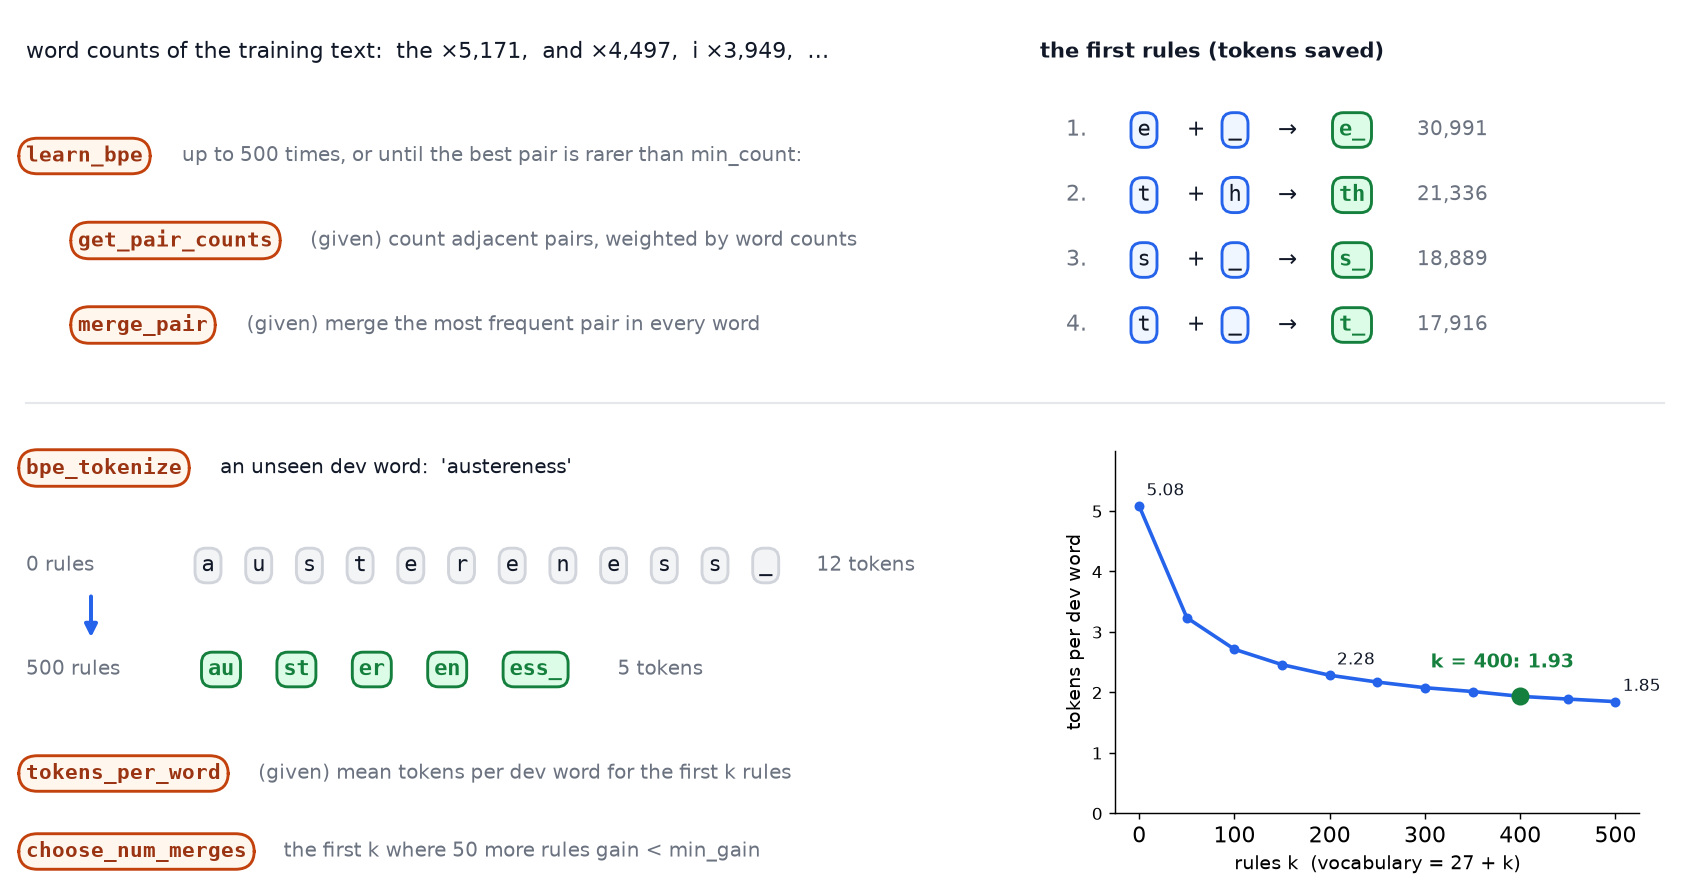 e_ (30,991), t + h -> th (21,336), s + _ -> s_ (18,889), t + _ -> t_ (17,916). bpe_tokenize on the unseen dev word &#x27;austereness&#x27;: 12 tokens with 0 rules, and au st er en ess_ (5 tokens) with 500 rules. tokens_per_word and choose_num_merges: a line chart of the mean tokens per dev word against the number of rules k, 0: 5.08, 50: 3.23, 100: 2.71, 150: 2.46, 200: 2.28, 250: 2.17, 300: 2.08, 350: 2.01, 400: 1.93, 450: 1.89, 500: 1.85; the chosen stopping point k = 400 is marked." width="720">

#### Given
- `get_pair_counts`, `merge_pair`, and `tokens_per_word(words, merges)` (mean BPE tokens per word).
- Code that learns 500 rules, measures the tokens per dev word for $k = 0, 50, \dots, 500$, and applies both stopping rules.

#### You write
1. `learn_bpe(word_counts, num_merges, min_count=1)` → `(merges, counts, splits)`: up to `num_merges` rules. Stop early if no pair is left, or if the most frequent pair occurs fewer than `min_count` times (that pair is not added). `counts[i]` is the count of rule `i` when it was chosen.
2. `bpe_tokenize(word, merges)`: the letters plus `END_OF_WORD`, then every rule in order.
3. `choose_num_merges(curve, min_gain)`: `curve` maps $k$ (increasing) to the tokens per dev word. Return the **first** $k$ whose gain to the next $k$, `curve[k] - curve[next k]`, is smaller than `min_gain`; if there is none, the last $k$.

#### Report
The given code reports `k_dev` (where your `choose_num_merges` stops, `min_gain = 0.05`) and `k_train` (how many rules your `learn_bpe` learns with `min_count = 200`). Look at both: what do the two rules agree on?

#### Grading (3 pts)
| Part | What | Points |
|---|---|---|
| 1.1 | `learn_bpe`: rules, counts, early stop | 1.5 |
| 1.2 | `bpe_tokenize` | 0.5 |
| 1.3 | `choose_num_merges` (0.5) and the reported stopping points (0.5) | 1 |

> Learning 500 rules takes about a minute in Colab, the second run with `min_count = 200` about 40 seconds.

In [6]:
def learn_bpe(word_counts: dict[str, int], num_merges: int,
              min_count: int = 1) -> tuple[list[tuple[str, str]], list[int], dict[str, list[str]]]:
    """Return the merge rules, the count of every rule when it was chosen, and the final split of every word."""
    ## YOUR_CODE_STARTS_HERE
    splits = {word: list(word) + [END_OF_WORD] for word in word_counts}  # every word: its letters + "_"
    merges, counts = [], []
    for _ in range(num_merges):
        pair_counts = get_pair_counts(splits, word_counts)
        if not pair_counts:                                   # every word is a single token already
            break
        best_pair = max(pair_counts, key=pair_counts.get)     # ties: the first pair counted
        if pair_counts[best_pair] < min_count:                # the training-side stopping rule
            break
        merges.append(best_pair)
        counts.append(pair_counts[best_pair])
        splits = {word: merge_pair(symbols, best_pair) for word, symbols in splits.items()}
    return merges, counts, splits
    ## YOUR_CODE_ENDS_HERE


def bpe_tokenize(word: str, merges: list[tuple[str, str]]) -> list[str]:
    """Split a word into its letters + END_OF_WORD, then apply every merge rule in the learned order."""
    ## YOUR_CODE_STARTS_HERE
    word_split = list(word) + [END_OF_WORD]
    for merge in merges:
        word_split = merge_pair(word_split, merge)
    return word_split
    ## YOUR_CODE_ENDS_HERE


def tokens_per_word(words: list[str], merges: list[tuple[str, str]]) -> float:
    """(given) Mean number of BPE tokens per word over the words of `words`; tokenize every different word once."""
    if not words:
        return 0.0
    word_counts = Counter(words)
    total_tokens = sum(count * len(bpe_tokenize(word, merges)) for word, count in word_counts.items())
    return total_tokens / len(words)


def choose_num_merges(curve: dict[int, float], min_gain: float) -> int:
    """The first k whose gain to the next k, curve[k] - curve[next k], is below min_gain; else the last k."""
    ## YOUR_CODE_STARTS_HERE
    if not curve:
        return 0
    sorted_keys = sorted(curve.keys())
    for i in range(len(sorted_keys) - 1):
        k = sorted_keys[i]
        next_k = sorted_keys[i + 1]
        gain = curve[k] - curve[next_k]
        if gain < min_gain:
            return k
    return sorted_keys[-1]
    ## YOUR_CODE_ENDS_HERE


# Learn 500 rules once; the first k rules are the rules of a run with k merges.
NUM_MERGES = 500
merges, merge_counts, splits = learn_bpe(WORD_COUNTS, NUM_MERGES)
print(f"[TASK1] Learned {len(merges)} rules; the first ten with their counts: "
      f"{[f'{a}+{b} {c:,}' for (a, b), c in zip(merges[:10], merge_counts[:10])]}")
print(f"Tokens saved on the training words by rule 1, 100, 200, 300, 400, 500: "
      f"{[merge_counts[i - 1] for i in (1, 100, 200, 300, 400, 500)]}")
for word in ["the", "king", "citizens", "gentleman"]:
    print(f"[TASK1]   train word {word!r:<12} -> {splits[word]}")
for word in list(dict.fromkeys(word for word in DEV_WORDS if word not in WORD_COUNTS))[:4]:
    print(f"[TASK1]   unseen dev word {word!r:<12} -> {bpe_tokenize(word, merges)}")

# The held-out side: tokens per dev word every 50 rules, and the gain of the next 50
curve = {k: tokens_per_word(DEV_WORDS, merges[:k]) for k in range(0, NUM_MERGES + 1, 50)}
print(f"{'rules k':>7} {'vocabulary':>10} {'tokens per dev word':>20} {'gain of the next 50':>20}")
for k in curve:
    gain = f"{curve[k] - curve[k + 50]:.3f}" if k + 50 in curve else "-"
    print(f"{k:>7} {len(BASE_SYMBOLS) + k:>10} {curve[k]:>20.3f} {gain:>20}")
k_dev = choose_num_merges(curve, min_gain=0.05)

# The training side: stop when the most frequent pair occurs fewer than 200 times
merges_200, counts_200, _ = learn_bpe(WORD_COUNTS, NUM_MERGES, min_count=200)
print(f"Held-out rule (min_gain = 0.05): stop at k = {k_dev} | training rule (min_count = 200): "
      f"{len(merges_200)} rules, the last one saves {counts_200[-1]} tokens")

report("1.3", {"k_dev": k_dev, "k_train": len(merges_200)})

# RESULT_CHECKING_POINT
print(f"[TASK1 RESULT_CHECKING_POINT] first rules: {[a + '+' + b for a, b in merges[:3]]} | rules learned: {len(merges)}")

[TASK1] Learned 500 rules; the first ten with their counts: ['e+_ 30,991', 't+h 21,336', 's+_ 18,889', 't+_ 17,916', 'd+_ 16,148', 'r+_ 12,096', 'y+_ 11,884', 'n+_ 10,889', 'o+u 10,439', 'o+_ 8,823']
Tokens saved on the training words by rule 1, 100, 200, 300, 400, 500: [30991, 1190, 481, 301, 201, 151]
[TASK1]   train word 'the'        -> ['the_']
[TASK1]   train word 'king'       -> ['king_']
[TASK1]   train word 'citizens'   -> ['ci', 'ti', 'z', 'en', 's_']
[TASK1]   train word 'gentleman'  -> ['gent', 'le', 'man_']
[TASK1]   unseen dev word 'warrants'   -> ['war', 'r', 'an', 'ts_']
[TASK1]   unseen dev word 'licence'    -> ['li', 'c', 'ence_']
[TASK1]   unseen dev word 'outstretch' -> ['ou', 't', 'st', 're', 't', 'ch_']
[TASK1]   unseen dev word 'unsoil'     -> ['un', 's', 'o', 'i', 'l_']
rules k vocabulary  tokens per dev word  gain of the next 50
      0         27                5.080                1.846
     50         77                3.235                0.522
    100      

In [7]:
# ------------------------- TESTS & EXPECTED OUTPUT -------------------------
#
# Your output of the cell above should match these lines. All values should match exactly.
# Hardcoding these values gives 0 points for the whole task.
#
# [TASK1] Learned 500 rules; the first ten with their counts: ['e+_ 30,991', 't+h 21,336', 's+_ 18,889', 't+_ 17,916', 'd+_ 16,148', 'r+_ 12,096', 'y+_ 11,884', 'n+_ 10,889', 'o+u 10,439', 'o+_ 8,823']
# [TASK1]   train word 'the'        -> ['the_']
# [TASK1]   train word 'king'       -> ['king_']
# [TASK1]   train word 'citizens'   -> ['ci', 'ti', 'z', 'en', 's_']
# [TASK1]   train word 'gentleman'  -> ['gent', 'le', 'man_']
# [TASK1]   unseen dev word 'warrants'   -> ['war', 'r', 'an', 'ts_']
# [TASK1]   unseen dev word 'licence'    -> ['li', 'c', 'ence_']
# [TASK1]   unseen dev word 'outstretch' -> ['ou', 't', 'st', 're', 't', 'ch_']
# [TASK1]   unseen dev word 'unsoil'     -> ['un', 's', 'o', 'i', 'l_']
# [TASK1 RESULT_CHECKING_POINT] first rules: ['e+_', 't+h', 's+_'] | rules learned: 500
#
# ---------------------------------------------------------------------------

# Task 2 (3 pts): Character n-gram models: how much history helps

**Goal.** Build character n-gram models for $n = 1, \dots, 6$ and find out how far a longer history helps, and why.

PS 05 built a bigram model over words. Here the tokens are **characters** ($|V| = 65$). The history of a character is the $n - 1$ characters before it: $n = 1$ has none (unigram), $n = 2$ is a character bigram model, and so on.

#### The model
For position $i$ of a text $t$, the history is $h = t_{i-n+1} \dots t_{i-1}$. With add-k smoothing (PS 05):

$$
P_k(c \mid h) = \frac{C(h\,c) + k}{C(h) + k\,|V|},
\qquad
\mathrm{PPL} = \exp\Big(-\frac{1}{N}\sum_{i=\mathrm{start}}^{|t|-1} \ln P_k(t_i \mid h_i)\Big),
\qquad N = |t| - \mathrm{start}.
$$

- $C(h\,c)$: how often $c$ follows $h$ in the training text; $C(h)$: how often $h$ occurs as a history.
- A history never seen in training has $C(h) = 0$, so every character gets $1/|V|$.
- Example ($n = 4$): in `First Citizen:`, the second `i` of `Citizen` has the history `Cit`: $P_k(\texttt{i} \mid \texttt{Cit}) = \frac{C(\texttt{Citi}) + k}{C(\texttt{Cit}) + 65\,k}$.

<img src="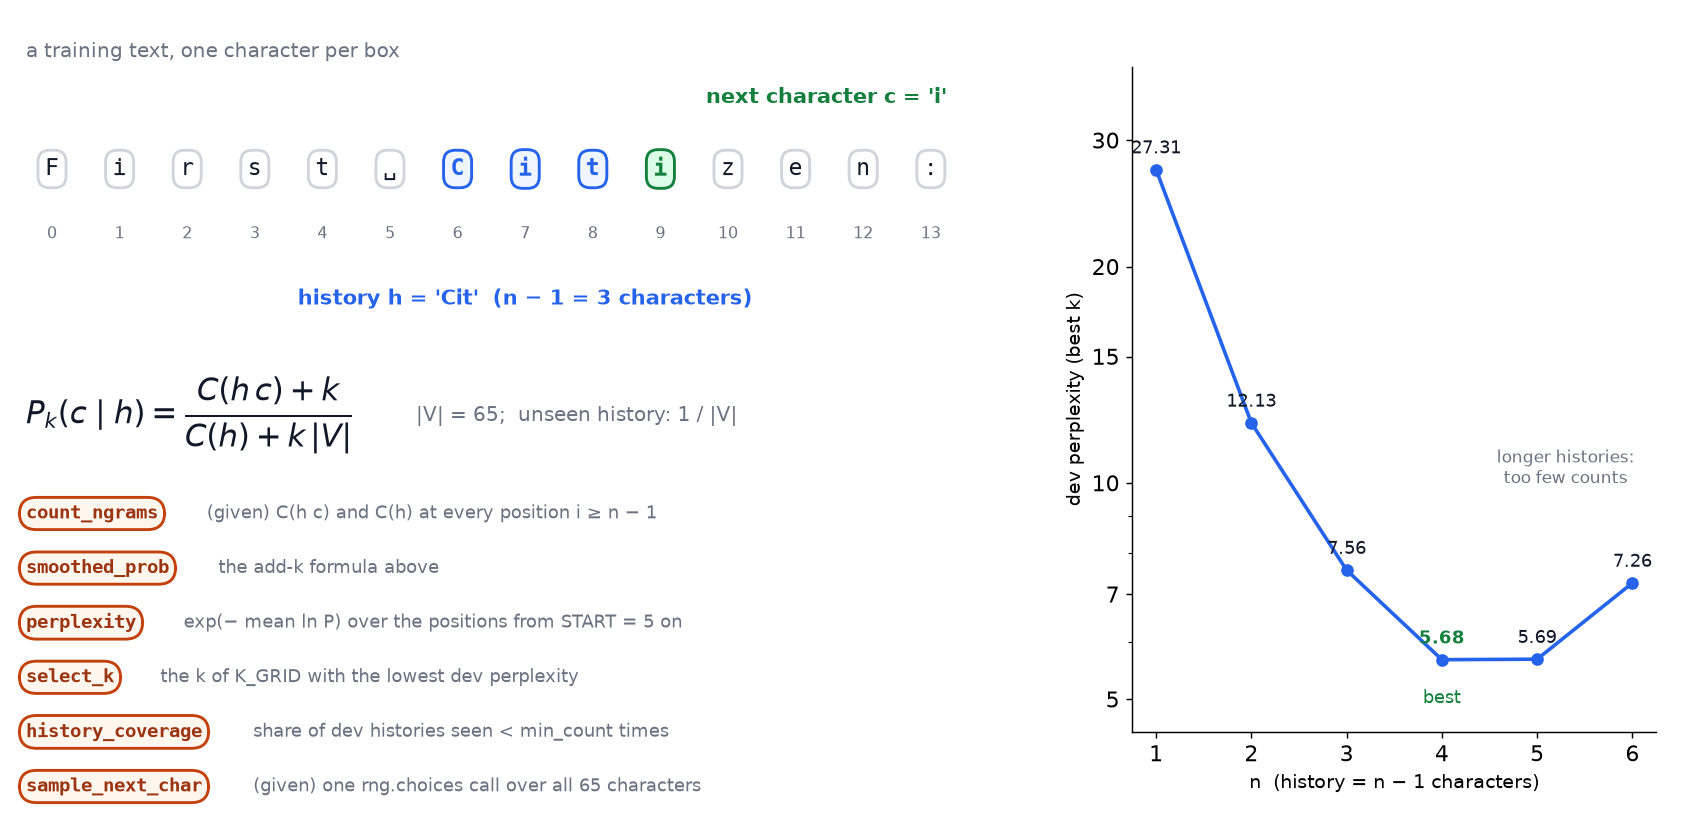" alt="The training text &#x27;First Citizen:&#x27; with one character per box; for n = 4, the second i of Citizen (position 9) has the history h = &#x27;Cit&#x27; (positions 6 to 8). The add-k formula P_k(c | h) = (C(h c) + k) / (C(h) + k |V|), with |V| = 65 and 1/|V| for an unseen history. count_ngrams counts C(h c) and C(h); smoothed_prob computes the formula; perplexity is exp(-mean ln P) from START = 5 on; select_k picks the k with the lowest dev perplexity; history_coverage measures the share of dev histories seen fewer than min_count times; sample_next_char draws one character with rng.choices. A line chart of the dev perplexity with the best k for n = 1 to 6: n = 1: 27.31, n = 2: 12.13, n = 3: 7.56, n = 4: 5.68, n = 5: 5.69, n = 6: 7.26; the best model is n = 4, and longer histories have too few counts." width="720">

#### Given
- `count_ngrams(text, n)`: the counts $C(h\,c)$ and $C(h)$; `sample_next_char`: draws a character from $P_k(\cdot \mid h)$.
- Code that counts all six models, chooses $k$ on the dev text, measures how many dev histories are rare, and samples 200 characters.

#### You write
1. `smoothed_prob(...)`: $P_k(c \mid h)$; it must also work for a history that was never counted.
2. `perplexity(...)`: the formula above over the positions `start, ..., len(text) - 1`, with `math.log`.
3. `select_k(...)`: the `k` of `k_grid` with the **lowest** perplexity, as `(best_k, best_perplexity)`; on a tie, the first.
4. `history_coverage(text, n, history_counts, start, min_count)`: the **fraction** of the positions `start, ..., len(text) - 1` whose history occurs **fewer than** `min_count` times in training.

#### Report
The given code reports `best_n` (the $n$ with the lowest dev perplexity) and `never_seen_percent_n6` (your `history_coverage` for $n = 6$ with `min_count = 1`, in percent). Compare the coverage for all $n$ with the perplexities: why does a longer history stop helping?

#### Grading (3 pts)
| Part | What | Points |
|---|---|---|
| 2.1 | `smoothed_prob` | 0.5 |
| 2.2 | `perplexity` | 1 |
| 2.3 | `select_k` | 0.5 |
| 2.4 | `history_coverage` (0.5) and the reported numbers (0.5) | 1 |

> A unigram perplexity above 65 means the model is worse than guessing uniformly: check the formula and the logarithm.

In [8]:
def count_ngrams(text: str, n: int) -> tuple[Counter, Counter]:
    """(given) Count (history, char) pairs and histories at every position i >= n - 1; history = text[i - n + 1 : i]."""
    ngram_counts, history_counts = Counter(), Counter()
    for i in range(n - 1, len(text)):
        history = text[i - n + 1 : i]
        ngram_counts[(history, text[i])] += 1
        history_counts[history] += 1
    return ngram_counts, history_counts


def smoothed_prob(ngram_counts: Counter, history_counts: Counter, history: str, char: str, k: float,
                  vocab_size: int) -> float:
    """Add-k estimate of P(char | history) = (C(history char) + k) / (C(history) + k |V|)."""
    ## YOUR_CODE_STARTS_HERE
    count_char = ngram_counts.get((history, char), 0)
    count_history = history_counts.get(history, 0)
    return (count_char + k) / (count_history + k * vocab_size)
    ## YOUR_CODE_ENDS_HERE


def perplexity(text: str, n: int, ngram_counts: Counter, history_counts: Counter, k: float, vocab_size: int,
               start: int) -> float:
    """exp(-mean ln P_k(text[i] | history)) over the positions i = start, ..., len(text) - 1."""
    ## YOUR_CODE_STARTS_HERE
    return math.exp(-sum(math.log(smoothed_prob(ngram_counts, history_counts, text[i - n + 1 : i], text[i], k, vocab_size)) for i in range(start, len(text))) / (len(text) - start))
    ## YOUR_CODE_ENDS_HERE


def select_k(text: str, n: int, ngram_counts: Counter, history_counts: Counter, k_grid: list[float],
             vocab_size: int, start: int) -> tuple[float, float]:
    """Return (best_k, best_perplexity): the k of k_grid with the lowest perplexity on text (ties: the first)."""
    ## YOUR_CODE_STARTS_HERE
    return min(((k, perplexity(text, n, ngram_counts, history_counts, k, vocab_size, start)) for k in k_grid), key=lambda x: x[1])
    ## YOUR_CODE_ENDS_HERE


def history_coverage(text: str, n: int, history_counts: Counter, start: int, min_count: int) -> float:
    """Fraction of the positions i = start, ..., len(text) - 1 whose history occurs fewer than min_count times."""
    ## YOUR_CODE_STARTS_HERE
    return sum(1 for i in range(start, len(text)) if history_counts.get(text[i - n + 1 : i], 0) < min_count) / (len(text) - start)
    ## YOUR_CODE_ENDS_HERE


def sample_next_char(history: str, ngram_counts: Counter, history_counts: Counter, k: float, vocab: list[str],
                     rng: random.Random) -> str:
    """(given) Draw the next character from P_k(. | history), with weights in the order of vocab."""
    probabilities = [smoothed_prob(ngram_counts, history_counts, history, ch, k, len(vocab)) for ch in vocab]
    return rng.choices(vocab, weights=probabilities, k=1)[0]


# Count every model on the training text, choose k on the dev text, and measure how many dev histories are rare
models = {}
for n in range(1, MAX_N + 1):
    ngram_counts, history_counts = count_ngrams(TRAIN_TEXT, n)
    best_k, dev_ppl = select_k(DEV_TEXT, n, ngram_counts, history_counts, K_GRID, VOCAB_SIZE, START)
    unseen = history_coverage(DEV_TEXT, n, history_counts, START, min_count=1)
    rare = history_coverage(DEV_TEXT, n, history_counts, START, min_count=5)
    models[n] = {"counts": (ngram_counts, history_counts), "k": best_k, "dev_ppl": dev_ppl, "unseen": unseen}
    print(f"n = {n} | {len(history_counts):>7,} histories | best k = {best_k:<5} | dev perplexity "
          f"{dev_ppl:6.3f} | dev histories never seen {100 * unseen:5.2f}%, seen < 5 times {100 * rare:5.2f}%")

# Checks of your functions on the bigram model (n = 2)
bigram_counts = models[2]["counts"]
print(f"[TASK2] n = 2: P(h | ' ') with k = 0.1 = {smoothed_prob(*bigram_counts, ' ', 'h', 0.1, VOCAB_SIZE):.5f} | "
      f"dev perplexity with k = 1.0: {perplexity(DEV_TEXT, 2, *bigram_counts, 1.0, VOCAB_SIZE, START):.3f} | "
      f"select_k: k = {models[2]['k']}, {models[2]['dev_ppl']:.3f}")
print(f"[TASK2] n = 3: share of dev histories seen fewer than 2 times: "
      f"{history_coverage(DEV_TEXT, 3, models[3]['counts'][1], START, 2):.5f}")

# The best n on the dev text, and its perplexity on the test text
best_n = min(models, key=lambda n: models[n]["dev_ppl"])
best = models[best_n]
test_ppl = perplexity(TEST_TEXT, best_n, *best["counts"], best["k"], VOCAB_SIZE, START)
print(f"Best model on the dev text: n = {best_n}, k = {best['k']} | test perplexity {test_ppl:.3f}")

# Sample 200 characters after a prompt
rng = random.Random(RANDOM_SEED)
generated = "ROMEO:\n"
for _ in range(200):
    history = generated[len(generated) - (best_n - 1):] if best_n > 1 else ""
    generated += sample_next_char(history, *best["counts"], best["k"], VOCAB, rng)
print("Sample:")
for line in generated.split("\n"):
    print(f"  {line}")

report("2.4", {"best_n": best_n, "never_seen_percent_n6": 100 * models[6]["unseen"]})

# RESULT_CHECKING_POINT
print(f"[TASK2 RESULT_CHECKING_POINT] bigram: k = {models[2]['k']}, dev perplexity {models[2]['dev_ppl']:.3f}")

n = 1 |       1 histories | best k = 0.001 | dev perplexity 27.313 | dev histories never seen  0.00%, seen < 5 times  0.00%
n = 2 |      65 histories | best k = 0.1   | dev perplexity 12.126 | dev histories never seen  0.00%, seen < 5 times  0.00%
n = 3 |   1,360 histories | best k = 0.1   | dev perplexity  7.565 | dev histories never seen  0.08%, seen < 5 times  0.11%
n = 4 |  10,899 histories | best k = 0.1   | dev perplexity  5.677 | dev histories never seen  1.04%, seen < 5 times  2.18%
n = 5 |  46,224 histories | best k = 0.01  | dev perplexity  5.686 | dev histories never seen  3.80%, seen < 5 times  9.14%
n = 6 | 125,229 histories | best k = 0.01  | dev perplexity  7.259 | dev histories never seen  9.82%, seen < 5 times 23.41%
[TASK2] n = 2: P(h | ' ') with k = 0.1 = 0.06913 | dev perplexity with k = 1.0: 12.132 | select_k: k = 0.1, 12.126
[TASK2] n = 3: share of dev histories seen fewer than 2 times: 0.00085
Best model on the dev text: n = 4, k = 0.1 | test perplexity 7.113
Sam

In [9]:
# ------------------------- TESTS & EXPECTED OUTPUT -------------------------
#
# Your output of the cell above should match these lines. All values should match exactly.
# Hardcoding these values gives 0 points for the whole task.
#
# [TASK2] n = 2: P(h | ' ') with k = 0.1 = 0.06913 | dev perplexity with k = 1.0: 12.132 | select_k: k = 0.1, 12.126
# [TASK2] n = 3: share of dev histories seen fewer than 2 times: 0.00085
# [TASK2 RESULT_CHECKING_POINT] bigram: k = 0.1, dev perplexity 12.126
#
# ---------------------------------------------------------------------------

# Task 3 (14 pts): A small Transformer

**Goal.** Understand *why* the Transformer of the lecture is built the way it is, by changing it, testing it, and taking it apart.

The model is the one of PS 06: decoder-only, pre-LN as in GPT-2, trained as a **character** language model on the text of Task 2.

| Part | You write | You find out | Points |
|---|---|---|---|
| 3.1 | multi-head attention as a few tensor operations | Is it the same as a loop-by-loop version? How much faster? | 2.5 |
| 3.2 | RMSNorm; a block with the norm before or after each sub-layer | What does each norm do to a row? | 1.5 |
| 3.3 | a warm-up **and the experiments** | What if the mask, the positions, the scaling, or the norm change? | 2 |
| 3.4 | two tests: can a model see the future? is a batch built correctly? | Which models and batch functions can you trust? | 2.5 |
| 3.5 | the gradients of the loss and of a linear layer, one AdamW step | Do your formulas match PyTorch? | 2.5 |
| 3.6 | switching off parts of $W_Q$, $W_K$, $W_V$, $W_O$, **and the ablations** | Which parts does the trained model need? | 1 |
| 3.7 | SwiGLU, a rule that chooses the MLP width, **and the sweep** | How many neurons are enough? Does the nonlinearity matter? | 2 |

#### Attention
With $n$ positions, $d = 64$, $h = 4$ heads, and $d_k = d / h = 16$:

$$
\mathrm{Attention}(Q, K, V) = \mathrm{softmax}\Big(\frac{Q K^\top}{\sqrt{d_k}} + M\Big)\, V,
\qquad
M_{tj} = \begin{cases} 0 & j \le t \\ -\infty & j > t \end{cases},
\qquad
\mathrm{MHA}(X) = \mathrm{Concat}(\mathrm{head}_1, \dots, \mathrm{head}_h)\, W_O .
$$

<img src="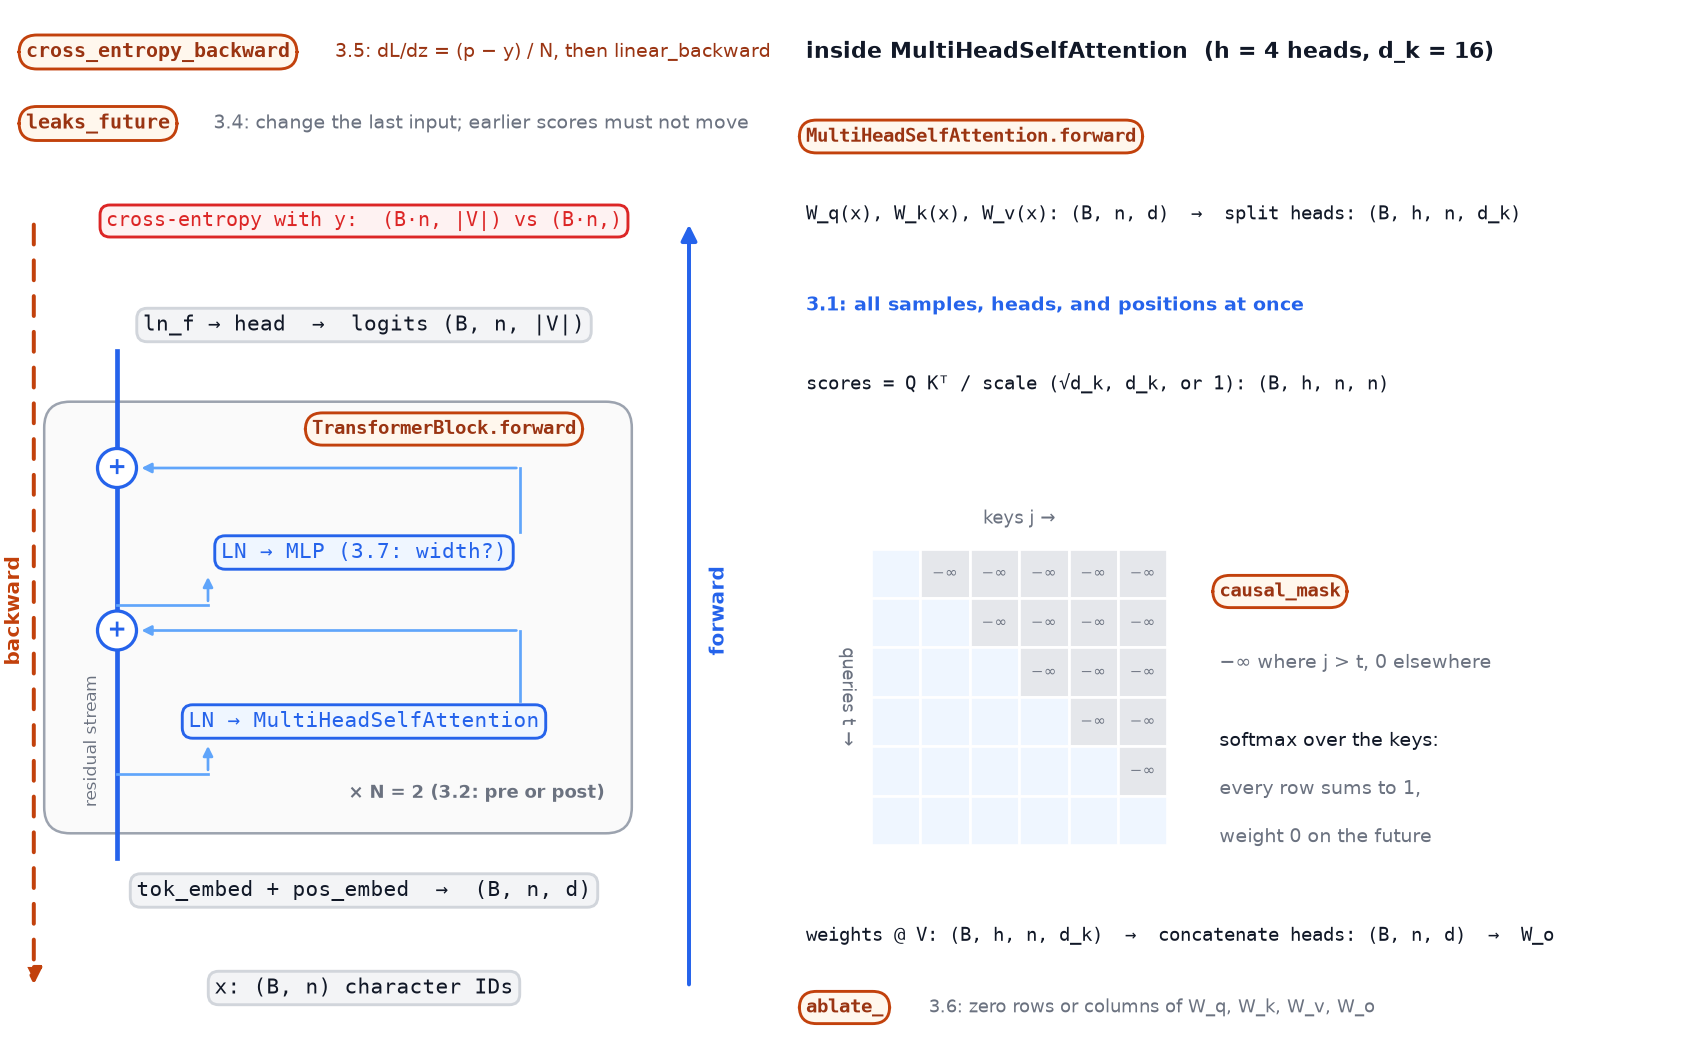" alt="Top left: cross_entropy_backward (3.5: dL/dz = (p - y) / N, then linear_backward) and leaks_future (3.4: change the last input; earlier scores must not move). The model from bottom to top: x of shape (B, n) character IDs; tok_embed + pos_embed gives (B, n, d); N = 2 TransformerBlocks (TransformerBlock.forward): the residual stream passes LN then MultiHeadSelfAttention, whose output is added back, then LN then the MLP (d to 4d to d), whose output is added back; ln_f and head give logits (B, n, |V|); the cross-entropy with y uses shapes (B·n, |V|) and (B·n,). A blue forward arrow points up and a dashed orange backward arrow points down. The blocks are pre-LN, or post-LN in 3.2. Inside MultiHeadSelfAttention, written in 3.1 for all samples, heads, and positions at once (h = 4, d_k = 16): W_q(x), W_k(x), W_v(x) of shape (B, n, d) are split into heads (B, h, n, d_k); the scores Q K^T divided by the scale (sqrt(d_k), d_k, or 1) have shape (B, h, n, n); a 6 by 6 grid shows -inf above the diagonal (causal_mask is -inf where j > t and 0 elsewhere); the softmax over the keys makes every row sum to 1 with weight 0 on the future; weights @ V gives (B, h, n, d_k), the heads are concatenated to (B, n, d), and W_o mixes them. ablate_ (3.6) zeros rows or columns of W_q, W_k, W_v, W_o." width="720">

> **`nn.Linear` stores its weight transposed:** `nn.Linear(d_in, d_out).weight` has shape `(d_out, d_in)`, and the layer computes $y = x W^\top + b$. This matters in 3.5 and 3.6.
>
> Run the parts in order: 3.2 trains the model that 3.5 and 3.6 use.

## 3.1 (2.5 pts): Fast multi-head attention

`slow_attention(attn, x)` computes attention the way the formula reads: one sample, one head, one position at a time, with Python loops. It is correct and very slow.

#### You write
`MultiHeadSelfAttention.forward`: the **same numbers** for all samples, heads, and positions at once.
1. `self.W_q(x)`, `self.W_k(x)`, `self.W_v(x)`: all heads side by side, shape `(B, n, d)`.
2. Split the heads: `view` to `(B, n, h, d_k)`, then `transpose(1, 2)` to `(B, h, n, d_k)`.
3. Scores `q @ k.transpose(-2, -1)`, divided by `SCALES[self.scale](self.d_k)` ($\sqrt{d_k}$, $d_k$, or 1).
4. If `self.causal`: **add** `causal_mask(n)`.
5. Softmax over the **last** dimension; store the weights in `self.last_weights`.
6. `weights @ v`, then `transpose(1, 2)` and `reshape(B, n, d)`, then `self.W_o`.

#### Grading (2.5 pts)
Same output as `slow_attention` for all three scales, with and without the mask.

In [10]:
def causal_mask(n: int) -> torch.Tensor:
    """(n, n) float mask: -inf strictly above the diagonal (position t must not attend to j > t), 0 elsewhere."""
    return torch.triu(torch.full((n, n), float("-inf")), diagonal=1)


SCALES = {"sqrt": lambda d_k: math.sqrt(d_k), "dk": lambda d_k: float(d_k), "none": lambda d_k: 1.0}


class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model: int, num_heads: int, causal: bool = True, scale: str = "sqrt") -> None:
        super().__init__()
        assert d_model % num_heads == 0 and scale in SCALES
        self.num_heads, self.d_k = num_heads, d_model // num_heads
        self.causal, self.scale = causal, scale
        self.W_q = nn.Linear(d_model, d_model)  # the W_Q of all heads side by side
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.last_weights = None                # attention weights of the last forward pass, (B, h, n, n)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: (B, n, d) -> (B, n, d), all samples, heads, and positions at once; stores the weights (B, h, n, n)."""
        ## YOUR_CODE_STARTS_HERE
        B, n, d = x.shape
        d_k = self.d_k
        q_all, k_all, v_all = self.W_q(x), self.W_k(x), self.W_v(x)  # (B, n, d): all heads side by side
        q_all = q_all.view(B, n, self.num_heads, d_k).transpose(1, 2)  # (B, h, n, d_k)
        k_all = k_all.view(B, n, self.num_heads, d_k).transpose(1, 2)  # (B, h, n, d_k)
        v_all = v_all.view(B, n, self.num_heads, d_k).transpose(1, 2)  # (B, h, n, d_k)
        scores = torch.matmul(q_all, k_all.transpose(-2, -1)) / SCALES[self.scale](d_k)
        if self.causal:
            mask = causal_mask(n).to(x.device)  # (n, n)
            scores = scores + mask.unsqueeze(0).unsqueeze(0)  # (B, h, n, n)
        weights = torch.softmax(scores, dim=-1)  # (B, h, n, n)
        self.last_weights = weights
        heads_out = torch.matmul(weights, v_all)  # (B, h, n, d_k)
        heads_out = heads_out.transpose(1, 2).contiguous().view(B, n, d)  # (B, n, d)
        return self.W_o(heads_out)
        ## YOUR_CODE_ENDS_HERE


def slow_attention(attn: MultiHeadSelfAttention, x: torch.Tensor) -> torch.Tensor:
    """The same computation as MultiHeadSelfAttention.forward, one sample, head, and position at a time."""
    B, n, d = x.shape
    d_k = attn.d_k
    q_all, k_all, v_all = attn.W_q(x), attn.W_k(x), attn.W_v(x)    # (B, n, d): all heads side by side
    heads_out = torch.zeros(B, n, d)
    for b in range(B):
        for head in range(attn.num_heads):
            cols = slice(head * d_k, (head + 1) * d_k)               # the d_k numbers of this head
            for t in range(n):
                visible = list(range(t + 1)) if attn.causal else list(range(n))  # the positions t may read
                scores = torch.stack([q_all[b, t, cols] @ k_all[b, j, cols] for j in visible])
                weights = torch.softmax(scores / SCALES[attn.scale](d_k), dim=0)
                heads_out[b, t, cols] = sum(w * v_all[b, j, cols] for w, j in zip(weights, visible))
    return attn.W_o(heads_out)


# Same numbers as the slow version: three scales, with and without the mask
x_check = torch.randn(2, 12, D_MODEL, generator=torch.Generator().manual_seed(RANDOM_SEED)) * 4
all_equal = True
for causal in (True, False):
    for scale in ("sqrt", "dk", "none"):
        torch.manual_seed(RANDOM_SEED)
        attn = MultiHeadSelfAttention(D_MODEL, NUM_HEADS, causal=causal, scale=scale)
        with torch.no_grad():
            difference = (attn(x_check) - slow_attention(attn, x_check)).abs().max().item()
        all_equal = all_equal and difference < 1e-5
        print(f"[TASK3.1] causal = {causal!s:<5} scale = {scale:<4} | same as the slow version: {difference < 1e-5} | "
              f"weights {tuple(attn.last_weights.shape)}")

# How much faster? One batch of 4 windows of 64 characters
torch.manual_seed(RANDOM_SEED)
attn = MultiHeadSelfAttention(D_MODEL, NUM_HEADS)
x_time = torch.randn(4, CONTEXT_LENGTH, D_MODEL)
with torch.no_grad():
    start = time.perf_counter()
    slow_attention(attn, x_time)
    slow_seconds = time.perf_counter() - start
    start = time.perf_counter()
    attn(x_time)
    fast_seconds = time.perf_counter() - start
print(f"One batch of 4 x {CONTEXT_LENGTH} positions: slow {slow_seconds:.2f} s, fast {1000 * fast_seconds:.2f} ms "
      f"(about {slow_seconds / fast_seconds:,.0f} times faster on this machine)")
print(f"[TASK3.1] The fast version is at least 50 times faster: {slow_seconds / fast_seconds >= 50}")

# RESULT_CHECKING_POINT
print(f"[TASK3.1 RESULT_CHECKING_POINT] same as the slow version in all 6 settings: {all_equal}")

[TASK3.1] causal = True  scale = sqrt | same as the slow version: True | weights (2, 4, 12, 12)
[TASK3.1] causal = True  scale = dk   | same as the slow version: True | weights (2, 4, 12, 12)
[TASK3.1] causal = True  scale = none | same as the slow version: True | weights (2, 4, 12, 12)
[TASK3.1] causal = False scale = sqrt | same as the slow version: True | weights (2, 4, 12, 12)
[TASK3.1] causal = False scale = dk   | same as the slow version: True | weights (2, 4, 12, 12)
[TASK3.1] causal = False scale = none | same as the slow version: True | weights (2, 4, 12, 12)
One batch of 4 x 64 positions: slow 0.16 s, fast 0.27 ms (about 602 times faster on this machine)
[TASK3.1] The fast version is at least 50 times faster: True
[TASK3.1 RESULT_CHECKING_POINT] same as the slow version in all 6 settings: True


In [11]:
# ------------------------- TESTS & EXPECTED OUTPUT -------------------------
#
# Your output of the cell above should match these lines. All values should match exactly.
# Hardcoding these values gives 0 points for the whole task.
#
# [TASK3.1] causal = True  scale = sqrt | same as the slow version: True | weights (2, 4, 12, 12)
# [TASK3.1] causal = True  scale = dk   | same as the slow version: True | weights (2, 4, 12, 12)
# [TASK3.1] causal = True  scale = none | same as the slow version: True | weights (2, 4, 12, 12)
# [TASK3.1] causal = False scale = sqrt | same as the slow version: True | weights (2, 4, 12, 12)
# [TASK3.1] causal = False scale = dk   | same as the slow version: True | weights (2, 4, 12, 12)
# [TASK3.1] causal = False scale = none | same as the slow version: True | weights (2, 4, 12, 12)
# [TASK3.1] The fast version is at least 50 times faster: True
# [TASK3.1 RESULT_CHECKING_POINT] same as the slow version in all 6 settings: True
#
# ---------------------------------------------------------------------------

## 3.2 (1.5 pts): Which norm, and where?

$$
\mathrm{LayerNorm}(x) = \gamma \odot \frac{x - \mu}{\sqrt{\sigma^2 + \varepsilon}} + \beta,
\qquad
\mathrm{RMSNorm}(x) = \gamma \odot \frac{x}{\sqrt{\tfrac{1}{d}\sum_i x_i^2 + \varepsilon}} .
$$

RMSNorm (Llama, Qwen, and others) does not subtract the mean and has no shift $\beta$.

| Placement | Update 1 | Update 2 | Used by |
|---|---|---|---|
| pre-LN | $x \leftarrow x + \mathrm{MHA}(\mathrm{LN}_1(x))$ | $x \leftarrow x + \mathrm{MLP}(\mathrm{LN}_2(x))$ | GPT-2, our model |
| post-LN | $x \leftarrow \mathrm{LN}_1(x + \mathrm{MHA}(x))$ | $x \leftarrow \mathrm{LN}_2(x + \mathrm{MLP}(x))$ | the original Transformer (2017) |

#### You write
1. `RMSNorm.forward`: the formula over the **last** dimension, with `self.weight` ($\gamma$) and `self.eps` ($\varepsilon$).
2. `TransformerBlock.forward`: the two updates of `self.placement` (`"pre"` or `"post"`), in this order.

#### Given
The rest of the model (a post-LN model has no final norm), `evaluate_perplexity`, `train_model`, `generate`, and the code that trains the **main model** (about 1.5 minutes).

#### Grading (1.5 pts)
`RMSNorm.forward` (0.75) and `TransformerBlock.forward`, both placements (0.75).

In [12]:
class RMSNorm(nn.Module):
    def __init__(self, d_model: int, eps: float = 1e-5) -> None:
        super().__init__()
        self.weight = nn.Parameter(torch.ones(d_model))  # gamma
        self.eps = eps

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """gamma * x / sqrt(mean(x^2) + eps) over the last dimension."""
        ## YOUR_CODE_STARTS_HERE
        rms = torch.sqrt(torch.mean(x ** 2, dim=-1, keepdim=True) + self.eps)
        return self.weight * x / rms
        ## YOUR_CODE_ENDS_HERE


def make_norm(kind: str, d_model: int) -> nn.Module:
    """"layer": nn.LayerNorm; "rms": RMSNorm."""
    return nn.LayerNorm(d_model) if kind == "layer" else RMSNorm(d_model)


class TransformerBlock(nn.Module):
    def __init__(self, d_model: int, num_heads: int, norm: str = "layer", placement: str = "pre",
                 causal: bool = True, scale: str = "sqrt") -> None:
        super().__init__()
        assert placement in ("pre", "post")
        self.placement = placement
        self.ln1 = make_norm(norm, d_model)
        self.attn = MultiHeadSelfAttention(d_model, num_heads, causal=causal, scale=scale)
        self.ln2 = make_norm(norm, d_model)
        self.mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """(B, n, d) -> (B, n, d): pre-LN x + MHA(LN(x)), x + MLP(LN(x)); post-LN LN(x + MHA(x)), LN(x + MLP(x))."""
        ## YOUR_CODE_STARTS_HERE
        if self.placement == "pre":
            x = x + self.attn(self.ln1(x))  # the norm only on the sub-layer's input; the residual keeps x
            x = x + self.mlp(self.ln2(x))
        else:
            x = self.ln1(x + self.attn(x))  # the norm after the residual sum
            x = self.ln2(x + self.mlp(x))
        return x
        ## YOUR_CODE_ENDS_HERE


class TinyTransformerLM(nn.Module):
    """Decoder-only: embeddings + learned positions -> N blocks -> final norm (pre-LN only) -> logits."""

    def __init__(self, vocab_size: int, context_length: int, d_model: int, num_heads: int, num_layers: int,
                 norm: str = "layer", placement: str = "pre", causal: bool = True, scale: str = "sqrt",
                 positions: bool = True) -> None:
        super().__init__()
        self.context_length, self.positions = context_length, positions
        self.tok_embed = nn.Embedding(vocab_size, d_model)
        self.pos_embed = nn.Embedding(context_length, d_model)
        self.blocks = nn.ModuleList([TransformerBlock(d_model, num_heads, norm, placement, causal, scale)
                                     for _ in range(num_layers)])
        self.ln_f = make_norm(norm, d_model) if placement == "pre" else nn.Identity()
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        """idx: (B, n) character IDs with n <= context_length -> logits (B, n, |V|)."""
        x = self.tok_embed(idx)
        if self.positions:
            x = x + self.pos_embed(torch.arange(idx.size(1), device=idx.device))
        for block in self.blocks:
            x = block(x)
        return self.head(self.ln_f(x))


@torch.no_grad()
def evaluate_perplexity(model: nn.Module, ids: torch.Tensor, context_length: int, batch_size: int = 256,
                        max_windows: int | None = None) -> float:
    """exp(mean cross-entropy) over all targets of the non-overlapping windows of ids (the first max_windows)."""
    model.eval()
    num_windows = (len(ids) - 1) // context_length
    if max_windows is not None:
        num_windows = min(num_windows, max_windows)
    x = ids[: num_windows * context_length].view(num_windows, context_length)
    y = ids[1 : num_windows * context_length + 1].view(num_windows, context_length)
    total_loss = 0.0
    for i in range(0, num_windows, batch_size):
        logits = model(x[i : i + batch_size])
        total_loss += F.cross_entropy(logits.reshape(-1, logits.size(-1)), y[i : i + batch_size].reshape(-1),
                                      reduction="sum").item()
    return math.exp(total_loss / y.numel())


def train_model(model: nn.Module, steps: int, lr: float, weight_decay: float = 0.0, lr_schedule=None,
                log_every: int = 0) -> list[float]:
    """AdamW on random training windows; lr_schedule(step) gives the learning rate of step 1, 2, ... (None: lr)."""
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    generator = torch.Generator().manual_seed(RANDOM_SEED)
    losses = []
    for step in range(1, steps + 1):
        if lr_schedule is not None:
            for group in optimizer.param_groups:
                group["lr"] = lr_schedule(step)
        model.train()
        x, y = get_batch(TRAIN_IDS, BATCH_SIZE, CONTEXT_LENGTH, generator)
        logits = model(x)
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        if log_every and (step == 1 or step % log_every == 0):
            print(f"Step {step:4d} | train loss {losses[-1]:.4f} | mean of the last {log_every} steps "
                  f"{np.mean(losses[-log_every:]):.4f}")
    return losses


@torch.no_grad()
def generate(model: nn.Module, prompt: str, length: int, generator: torch.Generator) -> str:
    """Sample `length` characters after `prompt`, one at a time, from the model's next-character distribution."""
    model.eval()
    idx = encode(prompt).unsqueeze(0)                          # (1, n)
    for _ in range(length):
        logits = model(idx[:, -model.context_length:])[:, -1]  # the scores at the last position, (1, |V|)
        next_id = torch.multinomial(torch.softmax(logits, dim=-1), 1, generator=generator)
        idx = torch.cat([idx, next_id], dim=1)
    return decode(idx[0])


# What the two norms do to one row
row = torch.tensor([[1.0, 2.0, 3.0]])
with torch.no_grad():
    print(f"[TASK3.2] RMSNorm([1, 2, 3])   = {[round(v, 3) for v in RMSNorm(3)(row)[0].tolist()]}  (the mean is kept)")
    print(f"[TASK3.2] LayerNorm([1, 2, 3]) = {[round(v, 3) for v in nn.LayerNorm(3)(row)[0].tolist()]}  (mean 0)")

# Where the norm sits: rows with mean about 1 and spread about 3 go into a block
x_block = torch.randn(2, 8, D_MODEL, generator=torch.Generator().manual_seed(RANDOM_SEED)) * 3 + 1
for placement in ("pre", "post"):
    torch.manual_seed(RANDOM_SEED)
    block = TransformerBlock(D_MODEL, NUM_HEADS, placement=placement)
    with torch.no_grad():
        out = block(x_block)
    print(f"[TASK3.2] {placement:<4}-LN block: output {tuple(out.shape)} | mean of a row {out.mean(-1).mean():.3f} | "
          f"spread of a row {out.std(-1, unbiased=False).mean():.3f}")

# The main model: 2 pre-LN blocks, 1,000 steps
torch.manual_seed(RANDOM_SEED)
model = TinyTransformerLM(VOCAB_SIZE, CONTEXT_LENGTH, D_MODEL, NUM_HEADS, NUM_LAYERS)
print(f"[TASK3.2] TinyTransformerLM: {sum(p.numel() for p in model.parameters()):,} parameters | untrained dev "
      f"perplexity {evaluate_perplexity(model, DEV_IDS, CONTEXT_LENGTH):.2f}")
losses = train_model(model, NUM_STEPS, LEARNING_RATE, weight_decay=WEIGHT_DECAY, log_every=200)
dev_ppl = evaluate_perplexity(model, DEV_IDS, CONTEXT_LENGTH)
test_ppl = evaluate_perplexity(model, TEST_IDS, CONTEXT_LENGTH)
print(f"Transformer: dev perplexity {dev_ppl:.3f} | test perplexity {test_ppl:.3f}")
for name, value in NGRAM_REFERENCE.items():
    print(f"{name}: dev perplexity {value:.3f}")
sample = generate(model, "ROMEO:\n", 200, torch.Generator().manual_seed(RANDOM_SEED))
print("Sample:")
for line in sample.split("\n"):
    print(f"  {line}")

# RESULT_CHECKING_POINT
print(f"[TASK3.2 RESULT_CHECKING_POINT] RMSNorm and both blocks checked above | training loss at step 1: {losses[0]:.4f}")

[TASK3.2] RMSNorm([1, 2, 3])   = [0.463, 0.926, 1.389]  (the mean is kept)
[TASK3.2] LayerNorm([1, 2, 3]) = [-1.225, 0.0, 1.225]  (mean 0)
[TASK3.2] pre -LN block: output (2, 8, 64) | mean of a row 1.028 | spread of a row 3.016
[TASK3.2] post-LN block: output (2, 8, 64) | mean of a row 0.000 | spread of a row 1.000
[TASK3.2] TinyTransformerLM: 112,577 parameters | untrained dev perplexity 75.92
Step    1 | train loss 4.3259 | mean of the last 200 steps 4.3259
Step  200 | train loss 2.3317 | mean of the last 200 steps 2.5819
Step  400 | train loss 2.0836 | mean of the last 200 steps 2.1942
Step  600 | train loss 1.9216 | mean of the last 200 steps 2.0031
Step  800 | train loss 1.8064 | mean of the last 200 steps 1.8741
Step 1000 | train loss 1.7764 | mean of the last 200 steps 1.7904
Transformer: dev perplexity 6.513 | test perplexity 7.179
unigram (n = 1): dev perplexity 27.313
bigram (n = 2): dev perplexity 12.126
best n-gram (n = 4, k = 0.1): dev perplexity 5.677
Sample:
  ROMEO:
  M

In [13]:
# ------------------------- TESTS & EXPECTED OUTPUT -------------------------
#
# Your output of the cell above should match these lines. All values should match exactly.
# Hardcoding these values gives 0 points for the whole task.
#
# [TASK3.2] RMSNorm([1, 2, 3])   = [0.463, 0.926, 1.389]  (the mean is kept)
# [TASK3.2] LayerNorm([1, 2, 3]) = [-1.225, 0.0, 1.225]  (mean 0)
# [TASK3.2] pre -LN block: output (2, 8, 64) | mean of a row 1.028 | spread of a row 3.016
# [TASK3.2] post-LN block: output (2, 8, 64) | mean of a row -0.000 | spread of a row 1.000
# [TASK3.2] TinyTransformerLM: 112,577 parameters | untrained dev perplexity 75.92
# [TASK3.2 RESULT_CHECKING_POINT] RMSNorm and both blocks checked above | training loss at step 1: 4.3259
#
# ---------------------------------------------------------------------------

## 3.3 (2 pts): What if…?

You design and run the experiments. Each one changes **one** thing compared with the baseline and trains for 300 steps (about 4 minutes for all of them).

#### Given
- `new_model(num_layers=2, **changes)`: a fresh model with the same random start. The `changes` are the switches of `TinyTransformerLM`: `norm="rms"`, `scale="dk"` or `"none"`, `positions=False`, `causal=False`, `placement="post"`.
- `run_experiment(name, model, lr=0.003, warmup_steps=0)`: trains the model and returns a dict with its dev perplexity `"ppl"`, its **attention peak** `"peak"` (the mean largest attention weight of the last block; 1.0 = all weight on one position).

#### You write
1. `warmup_lr(step, peak_lr, warmup_steps)`: `peak_lr * step / warmup_steps` for steps $1, \dots,$ `warmup_steps`, then `peak_lr`; always `peak_lr` if `warmup_steps = 0`.
2. **The experiments.** For every question, decide which model to build and how to train it, run it, and fill `RESULTS_3_3`. Keep everything you are not asked to change as in the baseline (2 blocks, learning rate 0.003, no warm-up).

| Question | Report in `RESULTS_3_3` |
|---|---|
| The baseline: 2 pre-LN blocks, LayerNorm, scores ÷ $\sqrt{d_k}$, positions, and the mask | `baseline_ppl`, `peak_sqrt` |
| Does RMSNorm work as well as LayerNorm? | `rmsnorm_ppl` |
| What do ÷ $d_k$ and no scaling do to the attention, compared with ÷ $\sqrt{d_k}$? | `peak_dk`, `peak_none` |
| Does the model need position embeddings? | `no_positions_ppl` |
| Does the model need the causal mask? Also let it write a few lines with `generate`, and read them. | `no_mask_ppl` |
| Does the place of the norm matter in a deeper model with large steps? 4 blocks, learning rate 0.02, once pre-LN and once post-LN. | `pre_ln_4_ppl`, `post_ln_4_ppl` |
| Which n-gram model of Task 2 (`NGRAM_REFERENCE`) has about the same dev perplexity as your post-LN model? | `post_ln_matches_ngram_n` (its $n$) |
| Does a warm-up of 100 steps help post-LN in the same setting? | `post_ln_4_warmup_ppl` |

Keep the line `report("3.3", RESULTS_3_3)`: it prints your numbers for the grader. For every result, ask yourself *why* it comes out this way.

#### Grading (2 pts)
`warmup_lr` (0.5) and your reported numbers (1.5).

In [14]:
def warmup_lr(step: int, peak_lr: float, warmup_steps: int) -> float:
    """Linear warm-up: peak_lr * step / warmup_steps for step <= warmup_steps, then peak_lr (steps count from 1)."""
    ## YOUR_CODE_STARTS_HERE
    if warmup_steps > 0 and step <= warmup_steps:
        return peak_lr * step / warmup_steps
    return peak_lr
    ## YOUR_CODE_ENDS_HERE


def new_model(num_layers: int = NUM_LAYERS, **changes) -> TinyTransformerLM:
    """A fresh model with the same random start for every experiment; changes = the switches of TinyTransformerLM."""
    torch.manual_seed(RANDOM_SEED)
    return TinyTransformerLM(VOCAB_SIZE, CONTEXT_LENGTH, D_MODEL, NUM_HEADS, num_layers, **changes)


def run_experiment(name: str, model_: TinyTransformerLM, lr: float = LEARNING_RATE, warmup_steps: int = 0) -> dict:
    """Train for EXPERIMENT_STEPS steps; return the dev perplexity and the mean largest attention weight of the last
    block ("peak")."""
    start = time.time()
    train_model(model_, EXPERIMENT_STEPS, lr, lr_schedule=lambda step: warmup_lr(step, lr, warmup_steps))
    ppl = evaluate_perplexity(model_, DEV_IDS, CONTEXT_LENGTH, max_windows=EVAL_WINDOWS)
    x, _ = get_batch(DEV_IDS, 8, CONTEXT_LENGTH, torch.Generator().manual_seed(RANDOM_SEED))
    model_.eval()
    with torch.no_grad():
        model_(x)
    peak = model_.blocks[-1].attn.last_weights.max(-1).values.mean().item()
    print(f"{name:<40} | dev perplexity {ppl:6.2f} | attention peak {peak:.2f} | {time.time() - start:.0f} s")
    return {"ppl": ppl, "peak": peak}


print(f"[TASK3.3] warmup_lr(step, 0.02, 100) at the steps 1, 50, 100, 200: "
      f"{[round(warmup_lr(s, 0.02, 100), 4) for s in (1, 50, 100, 200)]} | warmup_steps = 0: {warmup_lr(7, 0.02, 0)}")

RESULTS_3_3 = dict.fromkeys(["baseline_ppl", "rmsnorm_ppl", "peak_sqrt", "peak_dk", "peak_none",
                             "no_positions_ppl", "no_mask_ppl", "pre_ln_4_ppl", "post_ln_4_ppl",
                             "post_ln_4_warmup_ppl", "post_ln_matches_ngram_n"])  # fill in every value below
## YOUR_CODE_STARTS_HERE
# The baseline: 2 pre-LN blocks, LayerNorm, scores / sqrt(d_k), positions, causal mask
baseline = run_experiment("baseline", new_model())
RESULTS_3_3["baseline_ppl"] = baseline["ppl"]
RESULTS_3_3["peak_sqrt"] = baseline["peak"]

# One change at a time, everything else as in the baseline
RESULTS_3_3["rmsnorm_ppl"] = run_experiment("RMSNorm instead of LayerNorm", new_model(norm="rms"))["ppl"]
RESULTS_3_3["peak_dk"] = run_experiment("scores / d_k", new_model(scale="dk"))["peak"]
RESULTS_3_3["peak_none"] = run_experiment("scores not scaled", new_model(scale="none"))["peak"]
RESULTS_3_3["no_positions_ppl"] = run_experiment("no position embeddings", new_model(positions=False))["ppl"]

no_mask_model = new_model(causal=False)
RESULTS_3_3["no_mask_ppl"] = run_experiment("no causal mask", no_mask_model)["ppl"]
print("What the model without the mask writes:")
for line in generate(no_mask_model, "ROMEO:\n", 200, torch.Generator().manual_seed(RANDOM_SEED)).split("\n"):
    print(f"  {line}")

# A deeper model with large steps: 4 blocks, learning rate 0.02, pre-LN vs. post-LN, then post-LN with a warm-up
RESULTS_3_3["pre_ln_4_ppl"] = run_experiment("4 blocks, lr 0.02, pre-LN", new_model(num_layers=4), lr=0.02)["ppl"]
RESULTS_3_3["post_ln_4_ppl"] = run_experiment("4 blocks, lr 0.02, post-LN",
                                              new_model(num_layers=4, placement="post"), lr=0.02)["ppl"]
RESULTS_3_3["post_ln_4_warmup_ppl"] = run_experiment("4 blocks, lr 0.02, post-LN, 100 warm-up steps",
                                                     new_model(num_layers=4, placement="post"), lr=0.02,
                                                     warmup_steps=100)["ppl"]

# The n-gram model of Task 2 whose dev perplexity is closest to the post-LN model's (n read from its name)
closest = min(NGRAM_REFERENCE, key=lambda name: abs(NGRAM_REFERENCE[name] - RESULTS_3_3["post_ln_4_ppl"]))
RESULTS_3_3["post_ln_matches_ngram_n"] = int(re.search(r"n = (\d+)", closest).group(1))
print(f"post-LN, 4 blocks: {RESULTS_3_3['post_ln_4_ppl']:.2f} | closest n-gram model: {closest} "
      f"({NGRAM_REFERENCE[closest]:.3f})")
## YOUR_CODE_ENDS_HERE

report("3.3", RESULTS_3_3)

# RESULT_CHECKING_POINT
print(f"[TASK3.3 RESULT_CHECKING_POINT] warm-up at step 25 of 100: {warmup_lr(25, 0.02, 100):.4f}")

[TASK3.3] warmup_lr(step, 0.02, 100) at the steps 1, 50, 100, 200: [0.0002, 0.01, 0.02, 0.02] | warmup_steps = 0: 0.02
baseline                                 | dev perplexity   9.40 | attention peak 0.41 | 3 s
RMSNorm instead of LayerNorm             | dev perplexity   9.35 | attention peak 0.40 | 3 s
scores / d_k                             | dev perplexity  10.49 | attention peak 0.32 | 3 s
scores not scaled                        | dev perplexity   9.14 | attention peak 0.56 | 3 s
no position embeddings                   | dev perplexity  11.11 | attention peak 0.29 | 3 s
no causal mask                           | dev perplexity   1.05 | attention peak 0.10 | 3 s
What the model without the mask writes:
  ROMEO:
  
  OO
  OOLOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOnOOOOOOOOOOOOOOEOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOROOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOLOOOOOOOROOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOO
4 blocks, lr 0.02, pre-LN                | dev perplexity   8.38 | 

In [15]:
# ------------------------- TESTS & EXPECTED OUTPUT -------------------------
#
# Your output of the cell above should match these lines. All values should match exactly.
# Hardcoding these values gives 0 points for the whole task.
#
# [TASK3.3] warmup_lr(step, 0.02, 100) at the steps 1, 50, 100, 200: [0.0002, 0.01, 0.02, 0.02] | warmup_steps = 0: 0.02
# [TASK3.3 RESULT_CHECKING_POINT] warm-up at step 25 of 100: 0.0050
#
# ---------------------------------------------------------------------------

## 3.4 (2.5 pts): Too good to be true?

A perplexity that looks too good often means that the model can see the answer. Below are **four models** (`model_variant("M1")` … `"M4"`) and **four batch functions** (`batch_B1` … `batch_B4`). Not all of them can be trusted.

#### You write
1. `leaks_future(model, ids, context_length)`: in `model.eval()` mode and without gradients, take the first `context_length` IDs as one window `(1, n)`, make a copy whose **last** ID is `(id + 1) % VOCAB_SIZE`, run both through the model, and return the largest absolute change of the logits at positions $0, \dots, n - 2$, as a `float`. A causal model returns exactly 0.
2. `batch_is_valid(x, y, text)`: `True` if and only if `y[:, :-1]` equals `x[:, 1:]`, and for every row `b`, `decode(x[b]) + decode(y[b, -1:])` occurs in `text`.

Run both tests. For every model and batch function, read its code and choose what describes it.

#### Question → `DIAGNOSIS`
One letter per model and batch function (a letter may be used more than once):
- **A.** nothing is wrong
- **B.** normalizes each feature over the **positions** of a window instead of over the features of one token
- **C.** the softmax runs over the **queries** (`dim=-2`) instead of the keys
- **D.** concatenates the heads **without** moving the head dimension back (no `transpose`)
- **E.** the targets are the inputs themselves
- **F.** the targets are shifted by **two** characters
- **G.** the windows can come from the dev and test text
- **H.** the mask also hides the diagonal

#### Grading (2.5 pts)
`leaks_future` (0.75), `batch_is_valid` (0.75), `DIAGNOSIS` (0.125 each).

In [16]:
@torch.no_grad()
def leaks_future(model: nn.Module, ids: torch.Tensor, context_length: int) -> float:
    """Largest change of the logits at positions 0..n-2 when only the last ID of the first window changes."""
    ## YOUR_CODE_STARTS_HERE
    model.eval()
    window = ids[:context_length].unsqueeze(0)              # the first window, (1, n)
    changed = window.clone()
    changed[0, -1] = (changed[0, -1] + 1) % VOCAB_SIZE      # change only the last ID
    change = (model(window) - model(changed))[:, :-1]       # the logits at positions 0, ..., n - 2
    return float(change.abs().max().item())
    ## YOUR_CODE_ENDS_HERE


def batch_is_valid(x: torch.Tensor, y: torch.Tensor, text: str) -> bool:
    """y is x shifted by one, and every window plus its last target occurs in text."""
    ## YOUR_CODE_STARTS_HERE
    if x.shape != y.shape or not torch.equal(y[:, :-1], x[:, 1:]):  # y must be x shifted by one
        return False
    return all(decode(x[b]) + decode(y[b, -1:]) in text for b in range(x.size(0)))
    ## YOUR_CODE_ENDS_HERE


# ----- four models and four batch functions
class _NormM3(nn.LayerNorm):
    def forward(self, x):
        mean = x.mean(dim=1, keepdim=True)
        var = x.var(dim=1, keepdim=True, unbiased=False)
        return self.weight * (x - mean) / torch.sqrt(var + self.eps) + self.bias


class _AttentionM1(MultiHeadSelfAttention):
    def forward(self, x):
        B, n, d = x.shape
        q, k, v = (W(x).view(B, n, self.num_heads, self.d_k).transpose(1, 2) for W in (self.W_q, self.W_k, self.W_v))
        weights = torch.softmax(q @ k.transpose(-2, -1) / math.sqrt(self.d_k) + causal_mask(n), dim=-2)
        return self.W_o((weights @ v).transpose(1, 2).reshape(B, n, d))


class _AttentionM4(MultiHeadSelfAttention):
    def forward(self, x):
        B, n, d = x.shape
        q, k, v = (W(x).view(B, n, self.num_heads, self.d_k).transpose(1, 2) for W in (self.W_q, self.W_k, self.W_v))
        weights = torch.softmax(q @ k.transpose(-2, -1) / math.sqrt(self.d_k) + causal_mask(n), dim=-1)
        return self.W_o((weights @ v).reshape(B, n, d))


def model_variant(name: str, seed: int = RANDOM_SEED) -> TinyTransformerLM:
    torch.manual_seed(seed)
    m = TinyTransformerLM(VOCAB_SIZE, CONTEXT_LENGTH, D_MODEL, NUM_HEADS, NUM_LAYERS)
    for block in m.blocks:
        if name == "M1" or name == "M4":
            replacement = (_AttentionM1 if name == "M1" else _AttentionM4)(D_MODEL, NUM_HEADS)
            replacement.load_state_dict(block.attn.state_dict())
            block.attn = replacement
        if name == "M3":
            block.ln1, block.ln2 = _NormM3(D_MODEL), _NormM3(D_MODEL)
    return m


def batch_B1(generator):
    starts = torch.randint(len(ALL_IDS) - CONTEXT_LENGTH - 1, (BATCH_SIZE,), generator=generator)
    x = torch.stack([ALL_IDS[s : s + CONTEXT_LENGTH] for s in starts.tolist()])
    y = torch.stack([ALL_IDS[s + 1 : s + CONTEXT_LENGTH + 1] for s in starts.tolist()])
    return x, y


def batch_B2(generator):
    return get_batch(TRAIN_IDS, BATCH_SIZE, CONTEXT_LENGTH, generator)


def batch_B3(generator):
    x, _ = get_batch(TRAIN_IDS, BATCH_SIZE, CONTEXT_LENGTH, generator)
    return x, x.clone()


def batch_B4(generator):
    starts = torch.randint(len(TRAIN_IDS) - CONTEXT_LENGTH - 2, (BATCH_SIZE,), generator=generator)
    x = torch.stack([TRAIN_IDS[s : s + CONTEXT_LENGTH] for s in starts.tolist()])
    y = torch.stack([TRAIN_IDS[s + 2 : s + CONTEXT_LENGTH + 2] for s in starts.tolist()])
    return x, y


# ----- run the tests
for name in ("M1", "M2", "M3", "M4"):
    change = leaks_future(model_variant(name), DEV_IDS, CONTEXT_LENGTH)
    print(f"model {name}: largest change of an earlier score {change:.1e} -> "
          f"{'LEAKS THE FUTURE' if change > 1e-6 else 'no leak'}")
print(f"[TASK3.4] check: the trained main model of 3.2 leaks: {leaks_future(model, DEV_IDS, CONTEXT_LENGTH) > 1e-6} | "
      f"a model built with causal=False leaks: {leaks_future(new_model(causal=False), DEV_IDS, CONTEXT_LENGTH) > 1e-6}")
x_ok, y_ok = get_batch(TRAIN_IDS, BATCH_SIZE, CONTEXT_LENGTH, torch.Generator().manual_seed(RANDOM_SEED))
print(f"[TASK3.4] check: get_batch on the training text is valid: {batch_is_valid(x_ok, y_ok, TRAIN_TEXT)} | "
      f"with x and y swapped: {batch_is_valid(y_ok, x_ok, TRAIN_TEXT)}")
batch_verdicts = {}
for name, batch_fn in (("B1", batch_B1), ("B2", batch_B2), ("B3", batch_B3), ("B4", batch_B4)):
    x, y = batch_fn(torch.Generator().manual_seed(RANDOM_SEED))
    batch_verdicts[name] = batch_is_valid(x, y, TRAIN_TEXT)
    print(f"batch function {name}: valid = {batch_verdicts[name]}")

## ANSWER_STARTS_HERE
DIAGNOSIS = {"M1": "C", "M2": "A", "M3": "B", "M4": "D", "B1": "G", "B2": "A", "B3": "E", "B4": "F"}
## ANSWER_ENDS_HERE

# RESULT_CHECKING_POINT
print(f"[TASK3.4 RESULT_CHECKING_POINT] leaks_future returns a float: "
      f"{isinstance(leaks_future(model, DEV_IDS, CONTEXT_LENGTH), float)}")

model M1: largest change of an earlier score 5.0e-02 -> LEAKS THE FUTURE
model M2: largest change of an earlier score 0.0e+00 -> no leak
model M3: largest change of an earlier score 1.4e-02 -> LEAKS THE FUTURE
model M4: largest change of an earlier score 1.7e-02 -> LEAKS THE FUTURE
[TASK3.4] check: the trained main model of 3.2 leaks: False | a model built with causal=False leaks: True
[TASK3.4] check: get_batch on the training text is valid: True | with x and y swapped: False
batch function B1: valid = False
batch function B2: valid = True
batch function B3: valid = False
batch function B4: valid = False
[TASK3.4 RESULT_CHECKING_POINT] leaks_future returns a float: True


In [17]:
# ------------------------- TESTS & EXPECTED OUTPUT -------------------------
#
# Your output of the cell above should match these lines. All values should match exactly.
# Hardcoding these values gives 0 points for the whole task.
#
# [TASK3.4] check: the trained main model of 3.2 leaks: False | a model built with causal=False leaks: True
# [TASK3.4] check: get_batch on the training text is valid: True | with x and y swapped: False
# [TASK3.4 RESULT_CHECKING_POINT] leaks_future returns a float: True
#
# ---------------------------------------------------------------------------

## 3.5 (2.5 pts): Backward and update without autograd

`loss.backward()` and `optimizer.step()` hide short formulas. Write them as plain tensor code (no `.backward()`, no `torch.optim`) and compare with PyTorch on the trained model of 3.2.

**Loss.** For $N$ predictions with scores $z_r$ and right characters $y_r$, the mean cross-entropy has the gradient

$$
\frac{\partial L}{\partial z_r} = \frac{1}{N}\big(\mathrm{softmax}(z_r) - \mathrm{onehot}(y_r)\big) \qquad \text{(predicted minus actual).}
$$

**Linear layer.** For $Y = X W^\top + b$ (`weight` $W$ of shape `(d_out, d_in)`) and $G = \partial L / \partial Y$:

$$
\frac{\partial L}{\partial X} = G\, W, \qquad \frac{\partial L}{\partial W} = G^\top X, \qquad \frac{\partial L}{\partial b} = \textstyle\sum_r G_r .
$$

**AdamW** (as in `torch.optim.AdamW`; step $t = 1, 2, \dots$; gradient $g$):

$$
\theta \leftarrow \theta (1 - \eta\lambda), \quad
m \leftarrow \beta_1 m + (1 - \beta_1)\, g, \quad
v \leftarrow \beta_2 v + (1 - \beta_2)\, g^2, \quad
\theta \leftarrow \theta - \eta\, \frac{m / (1 - \beta_1^t)}{\sqrt{v / (1 - \beta_2^t)} + \varepsilon}.
$$

#### You write
1. `cross_entropy_backward(logits, targets)`: logits `(N, V)`, targets `(N,)` → gradient `(N, V)`.
2. `linear_backward(x, weight, grad_out)` → `(grad_x, grad_weight, grad_bias)`.
3. `adamw_step(param, grad, m, v, step, lr, beta1, beta2, eps, weight_decay)` → new `(param, m, v)`; do not change the inputs in place.

#### Grading (2.5 pts)
`cross_entropy_backward` (0.75), `linear_backward` (1), `adamw_step` (0.75).

In [18]:
def cross_entropy_backward(logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
    """d(mean cross-entropy)/d(logits) = (softmax(logits) - onehot(targets)) / N, shape (N, V)."""
    ## YOUR_CODE_STARTS_HERE
    N, V = logits.shape
    one_hot = F.one_hot(targets, num_classes=V).to(logits.dtype)
    return (torch.softmax(logits, dim=-1) - one_hot) / N      # predicted minus actual, averaged over N
    ## YOUR_CODE_ENDS_HERE


def linear_backward(x: torch.Tensor, weight: torch.Tensor,
                    grad_out: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Y = x W^T + b with W of shape (d_out, d_in): return dL/dx (N, d_in), dL/dW (d_out, d_in), dL/db (d_out,)."""
    ## YOUR_CODE_STARTS_HERE
    grad_x = grad_out @ weight             # (N, d_out) @ (d_out, d_in) -> (N, d_in)
    grad_weight = grad_out.T @ x           # (d_out, N) @ (N, d_in) -> (d_out, d_in)
    grad_bias = grad_out.sum(dim=0)        # (d_out,)
    return grad_x, grad_weight, grad_bias
    ## YOUR_CODE_ENDS_HERE


def adamw_step(param: torch.Tensor, grad: torch.Tensor, m: torch.Tensor, v: torch.Tensor, step: int, lr: float,
               beta1: float, beta2: float, eps: float,
               weight_decay: float) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """One AdamW step as in torch.optim.AdamW; return new (param, m, v)."""
    ## YOUR_CODE_STARTS_HERE
    param = param * (1 - lr * weight_decay)                 # decoupled weight decay (new tensors, no in-place)
    m = beta1 * m + (1 - beta1) * grad
    v = beta2 * v + (1 - beta2) * grad ** 2
    m_hat = m / (1 - beta1 ** step)                           # bias corrections
    v_hat = v / (1 - beta2 ** step)
    param = param - lr * m_hat / (torch.sqrt(v_hat) + eps)
    return param, m, v
    ## YOUR_CODE_ENDS_HERE


def final_features(model: TinyTransformerLM, idx: torch.Tensor) -> torch.Tensor:
    """The vectors that enter the output layer: embeddings + positions -> blocks -> final norm, (B, n, d)."""
    x = model.tok_embed(idx) + model.pos_embed(torch.arange(idx.size(1)))
    for block in model.blocks:
        x = block(x)
    return model.ln_f(x)


# 1) The output layer of the trained model, on 4 dev windows: your formulas vs. autograd
x, y = get_batch(DEV_IDS, 4, CONTEXT_LENGTH, torch.Generator().manual_seed(RANDOM_SEED))
model.eval()
with torch.no_grad():
    features = final_features(model, x).reshape(-1, D_MODEL)        # (N, d), N = 4 * 64 predictions
features.requires_grad_(True)
targets = y.reshape(-1)
logits = model.head(features)                                       # (N, |V|)
loss = F.cross_entropy(logits, targets)
model.zero_grad()
loss.backward()
grad_logits = cross_entropy_backward(logits.detach(), targets)
grad_x, grad_w, grad_b = linear_backward(features.detach(), model.head.weight.detach(), grad_logits)
print(f"[TASK3.5] {len(targets)} predictions | shapes: dL/dz {tuple(grad_logits.shape)}, "
      f"dL/dx {tuple(grad_x.shape)}, dL/dW {tuple(grad_w.shape)}, dL/db {tuple(grad_b.shape)}")
checks = {"dL/dx": torch.allclose(grad_x, features.grad, atol=1e-6),
          "dL/dW": torch.allclose(grad_w, model.head.weight.grad, atol=1e-6),
          "dL/db": torch.allclose(grad_b, model.head.bias.grad, atol=1e-6)}
print(f"[TASK3.5] same as autograd: {checks}")
p_right = torch.softmax(logits.detach()[0], dim=-1)[targets[0]].item()
print(f"prediction 0: p(right character) = {p_right:.3f}, its score gradient = "
      f"{grad_logits[0, targets[0]].item():.5f} = ({p_right:.3f} - 1) / {len(targets)}")

# 2) Five AdamW steps on 6 numbers: your adamw_step vs. torch.optim.AdamW
torch.manual_seed(RANDOM_SEED)
param_torch = torch.randn(6, requires_grad=True)
param_hand, m_state, v_state = param_torch.detach().clone(), torch.zeros(6), torch.zeros(6)
start_values = param_hand.clone()
optimizer = optim.AdamW([param_torch], lr=0.01, betas=(0.9, 0.95), eps=1e-8, weight_decay=0.1)
for step in range(1, 6):
    grad = torch.randn(6) * 10 ** (step - 3)                         # gradients of very different sizes
    param_torch.grad = grad.clone()
    optimizer.step()
    param_hand, m_state, v_state = adamw_step(param_hand, grad, m_state, v_state, step, 0.01, 0.9, 0.95, 1e-8, 0.1)
    if step == 1:
        print(f"[TASK3.5] after step 1 every number moved by about lr = 0.01: "
              f"{[round(abs(d), 4) for d in (param_hand - start_values).tolist()]}")
adamw_ok = torch.allclose(param_hand, param_torch.detach(), atol=1e-6)
print(f"[TASK3.5] your adamw_step = torch.optim.AdamW after 5 steps: {adamw_ok} | "
      f"first values {[round(v, 4) for v in param_hand[:3].tolist()]}")

# RESULT_CHECKING_POINT
print(f"[TASK3.5 RESULT_CHECKING_POINT] gradients match: {all(checks.values())} | AdamW matches: {adamw_ok}")

[TASK3.5] 256 predictions | shapes: dL/dz (256, 65), dL/dx (256, 64), dL/dW (65, 64), dL/db (65,)
[TASK3.5] same as autograd: {'dL/dx': True, 'dL/dW': True, 'dL/db': True}
prediction 0: p(right character) = 0.074, its score gradient = -0.00362 = (0.074 - 1) / 256
[TASK3.5] after step 1 every number moved by about lr = 0.01: [0.0103, 0.0099, 0.0102, 0.0102, 0.0089, 0.0098]
[TASK3.5] your adamw_step = torch.optim.AdamW after 5 steps: True | first values [0.3155, 0.1494, 0.211]
[TASK3.5 RESULT_CHECKING_POINT] gradients match: True | AdamW matches: True


In [19]:
# ------------------------- TESTS & EXPECTED OUTPUT -------------------------
#
# Your output of the cell above should match these lines. All values should match exactly.
# Hardcoding these values gives 0 points for the whole task.
#
# [TASK3.5] 256 predictions | shapes: dL/dz (256, 65), dL/dx (256, 64), dL/dW (65, 64), dL/db (65,)
# [TASK3.5] same as autograd: {'dL/dx': True, 'dL/dW': True, 'dL/db': True}
# [TASK3.5] after step 1 every number moved by about lr = 0.01: [0.0103, 0.0099, 0.0102, 0.0102, 0.0089, 0.0098]
# [TASK3.5] your adamw_step = torch.optim.AdamW after 5 steps: True | first values [0.3155, 0.1494, 0.211]
# [TASK3.5 RESULT_CHECKING_POINT] gradients match: True | AdamW matches: True
#
# ---------------------------------------------------------------------------

## 3.6 (1 pt): Take the trained model apart

To find out what a part of a model does, switch it off (an **ablation**) and measure how much worse the model gets.

#### You write
1. `ablate_(layer, part, index=None)`: set parts of an `nn.Linear` to zero, **in place**. `layer.weight` has shape `(d_out, d_in)`.

| `part` | Set to zero |
|---|---|
| `"all"` | all of `weight` and `bias` |
| `"outputs"` | the rows `index` of `weight`, and `bias[index]` |
| `"inputs"` | the columns `index` of `weight` (the bias stays) |

2. **The ablations.** Each one on a fresh copy of the trained model of 3.2 (`copy.deepcopy(model)`), evaluated with `evaluate_perplexity(..., max_windows=EVAL_WINDOWS)` like `baseline_ppl`. Fill `RESULTS_3_6`:

| Question | Report in `RESULTS_3_6` |
|---|---|
| Does it matter whether you switch off the queries or the keys of block 1? Zero all of $W_Q$, then, on another copy, all of $W_K$. | `q_minus_k`: the first perplexity minus the second |
| Whose values matter more, block 1's or block 2's? Zero all of $W_V$ in each. | `block1_v_ppl`, `block2_v_ppl` |
| How much does one input feature of the queries matter? Zero input feature 0 of $W_Q$ in block 1. | `one_column_change`: its perplexity minus `baseline_ppl` |

After your ablations, the cell uses your `ablate_` to switch off the values of **one head** of block 1 at a time and prints the four perplexities. Do the heads matter equally? (Part 3 of the course looks inside the heads in detail.)

#### Grading (1 pt)
`ablate_` (0.5) and your reported numbers (0.5).

In [20]:
def ablate_(layer: nn.Linear, part: str, index=None) -> None:
    """Zero parts of an nn.Linear in place: "all", "outputs" (rows of weight + bias entries), "inputs" (columns)."""
    ## YOUR_CODE_STARTS_HERE
    with torch.no_grad():
        if part == "all":
            layer.weight.zero_()
            if layer.bias is not None:
                layer.bias.zero_()
        elif part == "outputs":                  # rows of weight = output features
            layer.weight[index] = 0.0
            if layer.bias is not None:
                layer.bias[index] = 0.0
        elif part == "inputs":                   # columns of weight = input features; the bias stays
            layer.weight[:, index] = 0.0
        else:
            raise ValueError(f"unknown part {part!r}")
    ## YOUR_CODE_ENDS_HERE


baseline_ppl = evaluate_perplexity(model, DEV_IDS, CONTEXT_LENGTH, max_windows=EVAL_WINDOWS)
print(f"[TASK3.6] the trained model of 3.2, nothing switched off: dev perplexity {baseline_ppl:.2f}")

RESULTS_3_6 = dict.fromkeys(["q_minus_k", "block1_v_ppl", "block2_v_ppl",
                             "one_column_change"])  # fill in every value below
## YOUR_CODE_STARTS_HERE
def ablated_ppl(block: int, matrix: str, part: str = "all", index=None) -> float:
    """Dev perplexity of a fresh copy of the trained model with part of one attention matrix zeroed."""
    broken = copy.deepcopy(model)
    ablate_(getattr(broken.blocks[block].attn, matrix), part, index)
    return evaluate_perplexity(broken, DEV_IDS, CONTEXT_LENGTH, max_windows=EVAL_WINDOWS)


q_ppl, k_ppl = ablated_ppl(0, "W_q"), ablated_ppl(0, "W_k")
RESULTS_3_6["q_minus_k"] = q_ppl - k_ppl
RESULTS_3_6["block1_v_ppl"] = ablated_ppl(0, "W_v")
RESULTS_3_6["block2_v_ppl"] = ablated_ppl(1, "W_v")
RESULTS_3_6["one_column_change"] = ablated_ppl(0, "W_q", "inputs", 0) - baseline_ppl
print(f"block 1: W_Q zeroed {q_ppl:.4f} | W_K zeroed {k_ppl:.4f} | W_V zeroed {RESULTS_3_6['block1_v_ppl']:.2f} || "
      f"block 2: W_V zeroed {RESULTS_3_6['block2_v_ppl']:.2f}")
## YOUR_CODE_ENDS_HERE

report("3.6", RESULTS_3_6)

# Given: one head at a time. Zero the values of head h of block 1 (the outputs 16h, ..., 16h + 15 of W_v).
head_size = D_MODEL // NUM_HEADS
head_ppl = []
for h in range(NUM_HEADS):
    broken = copy.deepcopy(model)
    ablate_(broken.blocks[0].attn.W_v, "outputs", slice(head_size * h, head_size * (h + 1)))
    head_ppl.append(evaluate_perplexity(broken, DEV_IDS, CONTEXT_LENGTH, max_windows=EVAL_WINDOWS))
print(f"block 1, the values of one head zeroed (heads 1-4): {[round(p, 2) for p in head_ppl]} | "
      f"nothing zeroed: {baseline_ppl:.2f}")
print(f"[TASK3.6] the original model is unchanged: "
      f"{evaluate_perplexity(model, DEV_IDS, CONTEXT_LENGTH, max_windows=EVAL_WINDOWS) == baseline_ppl}")

# RESULT_CHECKING_POINT
print(f"[TASK3.6 RESULT_CHECKING_POINT] ablations ran on copies; the original is unchanged")

[TASK3.6] the trained model of 3.2, nothing switched off: dev perplexity 6.35
block 1: W_Q zeroed 19.8850 | W_K zeroed 19.8850 | W_V zeroed 23.50 || block 2: W_V zeroed 8.59
[REPORT 3.6] {"q_minus_k": 0.0, "block1_v_ppl": 23.5006, "block2_v_ppl": 8.5883, "one_column_change": 0.0057}
block 1, the values of one head zeroed (heads 1-4): [14.49, 6.55, 7.04, 6.48] | nothing zeroed: 6.35
[TASK3.6] the original model is unchanged: True
[TASK3.6 RESULT_CHECKING_POINT] ablations ran on copies; the original is unchanged


In [21]:
# ------------------------- TESTS & EXPECTED OUTPUT -------------------------
#
# Your output of the cell above should match these lines. All values should match exactly.
# Hardcoding these values gives 0 points for the whole task.
#
# [TASK3.6] the trained model of 3.2, nothing switched off: dev perplexity 6.35
# [TASK3.6] the original model is unchanged: True
# [TASK3.6 RESULT_CHECKING_POINT] ablations ran on copies; the original is unchanged
#
# ---------------------------------------------------------------------------

## 3.7 (2 pts): How many neurons, and which nonlinearity?

The MLP of a block maps each token's 64 numbers to `width` neurons, applies a nonlinearity, and maps back to 64. GPT-2 uses `width` $= 4d$ (here 256) and GELU.

**SwiGLU** (Llama, Qwen, and others) is a *gated* MLP:

$$
\mathrm{SwiGLU}(x) = \big(\mathrm{SiLU}(x W_1^\top + b_1) \odot (x W_3^\top + b_3)\big)\, W_2^\top + b_2,
\qquad \mathrm{SiLU}(a) = a \cdot \sigma(a).
$$

It has three matrices instead of two, so 170 neurons give about as many weights as GELU with 256.

#### Given
`make_mlp(width, activation)` and `run_mlp_experiment(width, activation)`: replaces the MLP of both blocks, trains for 300 steps, and returns the dev perplexity (about 25 seconds per run in Colab).

#### You write
1. `SwiGLU.forward`: the formula, with `self.w1`, `self.w3`, `self.w2` and `F.silu`.
2. `choose_width(results, tolerance)`: `results` maps a width to its dev perplexity. Return the **smallest** width whose perplexity is at most `(1 + tolerance)` times the best one.
3. **The experiments.** Fill `RESULTS_3_7`:

| Question | Report in `RESULTS_3_7` |
|---|---|
| How many GELU neurons are enough? Try 32, 64, 128, 256, and 512, and choose with `tolerance = 0.03`. | `chosen_width`, `gelu_256_ppl` |
| Does the nonlinearity matter? Compare `"none"`, `"tanh"`, and `"relu"` with 256 neurons, and `"swiglu"` with 170. | `none_ppl`, `swiglu_ppl` |

#### Grading (2 pts)
`SwiGLU.forward` (0.5), `choose_width` (0.5), and your reported numbers (1).

In [22]:
class SwiGLU(nn.Module):
    def __init__(self, d_model: int, width: int) -> None:
        super().__init__()
        self.w1 = nn.Linear(d_model, width)  # the gate (through SiLU)
        self.w3 = nn.Linear(d_model, width)  # the values that pass
        self.w2 = nn.Linear(width, d_model)  # back to d_model

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """(SiLU(w1(x)) * w3(x)) -> w2."""
        ## YOUR_CODE_STARTS_HERE
        return self.w2(F.silu(self.w1(x)) * self.w3(x))
        ## YOUR_CODE_ENDS_HERE


def choose_width(results: dict[int, float], tolerance: float) -> int:
    """The smallest width whose perplexity is at most (1 + tolerance) * the best perplexity."""
    ## YOUR_CODE_STARTS_HERE
    best = min(results.values())
    return min(width for width, ppl in results.items() if ppl <= (1 + tolerance) * best)
    ## YOUR_CODE_ENDS_HERE


def make_mlp(width: int, activation: str) -> nn.Module:
    """An MLP d -> width -> d with the given nonlinearity, or a SwiGLU."""
    if activation == "swiglu":
        return SwiGLU(D_MODEL, width)
    nonlinearity = {"gelu": nn.GELU(), "relu": nn.ReLU(), "tanh": nn.Tanh(), "none": nn.Identity()}[activation]
    return nn.Sequential(nn.Linear(D_MODEL, width), nonlinearity, nn.Linear(width, D_MODEL))


def run_mlp_experiment(width: int, activation: str) -> float:
    """Train a model whose blocks use make_mlp(width, activation) for EXPERIMENT_STEPS steps; return its dev perplexity."""
    torch.manual_seed(RANDOM_SEED)
    m = TinyTransformerLM(VOCAB_SIZE, CONTEXT_LENGTH, D_MODEL, NUM_HEADS, NUM_LAYERS)
    for block in m.blocks:
        block.mlp = make_mlp(width, activation)
    start = time.time()
    train_model(m, EXPERIMENT_STEPS, LEARNING_RATE)
    ppl = evaluate_perplexity(m, DEV_IDS, CONTEXT_LENGTH, max_windows=EVAL_WINDOWS)
    mlp_weights = sum(p.numel() for block in m.blocks for p in block.mlp.parameters())
    print(f"{activation:<6} width {width:>4} | MLP weights (both blocks) {mlp_weights:>7,} | "
          f"dev perplexity {ppl:6.2f}")
    print(f"          ({time.time() - start:.0f} s)")
    return ppl


# The weight budget of the two MLPs that 3.7 compares
torch.manual_seed(RANDOM_SEED)
weights_gelu = sum(p.numel() for p in make_mlp(256, "gelu").parameters())
weights_swiglu = sum(p.numel() for p in make_mlp(170, "swiglu").parameters())
print(f"[TASK3.7] MLP weights per block: GELU with 256 neurons {weights_gelu:,} | SwiGLU with 170 neurons {weights_swiglu:,}")

RESULTS_3_7 = dict.fromkeys(["chosen_width", "gelu_256_ppl", "none_ppl", "swiglu_ppl"])  # fill in every value below
## YOUR_CODE_STARTS_HERE
gelu_ppl = {width: run_mlp_experiment(width, "gelu") for width in (32, 64, 128, 256, 512)}
RESULTS_3_7["chosen_width"] = choose_width(gelu_ppl, tolerance=0.03)
RESULTS_3_7["gelu_256_ppl"] = gelu_ppl[256]

activation_ppl = {activation: run_mlp_experiment(256, activation) for activation in ("none", "tanh", "relu")}
activation_ppl["swiglu"] = run_mlp_experiment(170, "swiglu")
RESULTS_3_7["none_ppl"] = activation_ppl["none"]
RESULTS_3_7["swiglu_ppl"] = activation_ppl["swiglu"]
print(f"GELU: { {width: round(ppl, 2) for width, ppl in gelu_ppl.items()} } -> chosen width "
      f"{RESULTS_3_7['chosen_width']} | other nonlinearities: "
      f"{ {name: round(ppl, 2) for name, ppl in activation_ppl.items()} }")
## YOUR_CODE_ENDS_HERE

report("3.7", RESULTS_3_7)

# RESULT_CHECKING_POINT
print(f"[TASK3.7 RESULT_CHECKING_POINT] SwiGLU output shape: {tuple(SwiGLU(D_MODEL, 170)(torch.zeros(2, 3, D_MODEL)).shape)}")

[TASK3.7] MLP weights per block: GELU with 256 neurons 33,088 | SwiGLU with 170 neurons 33,044
gelu   width   32 | MLP weights (both blocks)   8,384 | dev perplexity  10.23
          (3 s)
gelu   width   64 | MLP weights (both blocks)  16,640 | dev perplexity   9.96
          (2 s)
gelu   width  128 | MLP weights (both blocks)  33,152 | dev perplexity   9.64
          (2 s)
gelu   width  256 | MLP weights (both blocks)  66,176 | dev perplexity   9.43
          (3 s)
gelu   width  512 | MLP weights (both blocks) 132,224 | dev perplexity   9.19
          (4 s)
none   width  256 | MLP weights (both blocks)  66,176 | dev perplexity  10.62
          (2 s)
tanh   width  256 | MLP weights (both blocks)  66,176 | dev perplexity  10.15
          (3 s)
relu   width  256 | MLP weights (both blocks)  66,176 | dev perplexity   9.49
          (2 s)
swiglu width  170 | MLP weights (both blocks)  66,088 | dev perplexity   8.97
          (3 s)
GELU: {32: 10.23, 64: 9.96, 128: 9.64, 256: 9.43, 512: 9.19

In [23]:
# ------------------------- TESTS & EXPECTED OUTPUT -------------------------
#
# Your output of the cell above should match these lines. All values should match exactly.
# Hardcoding these values gives 0 points for the whole task.
#
# [TASK3.7] MLP weights per block: GELU with 256 neurons 33,088 | SwiGLU with 170 neurons 33,044
# [TASK3.7 RESULT_CHECKING_POINT] SwiGLU output shape: (2, 3, 64)
#
# ---------------------------------------------------------------------------

# BONUS (2 pts): Solve one task with an LLM

**Goal.**
Choose **one** task (Task 1, Task 2, or one part of Task 3), let an **LLM** solve it, run the LLM's code, and compare its result with the `TESTS & EXPECTED OUTPUT` cell and with your own solution.

**Steps.**
1. Give the LLM the task's description (the Markdown cell) and the code it depends on: the data-and-helpers cells and the task code cell with the empty `YOUR_CODE` regions. Ask it for the code of **all** `YOUR_CODE` regions of that task (functions and experiments; for 3.4 also the letters).
2. Run the generated code in a **copy of this notebook**: paste it into the task code cell of the copy and run the copy from the top. This keeps your own solution here unchanged. Do not submit the copy.
3. Fill in the answer cell below.

**What to deliver in the answer cell.**
1) **LLM used**: (name + version, e.g., "Llama-3-8B-Instruct", "GPT-x", "Claude-x", "Mistral-x", etc.). You may use any LLMs through any interface (API, web UI, local inference).
2) **Generated code**: the LLM's generated code for the task's regions (and, for 3.4, its letters). If you needed several attempts, paste the last one.
3) **Output**: the `RESULT_CHECKING_POINT` line that the LLM's code printed, or the error message if it failed.
4) **Comparison and reflection** (3–6 sentences): Does the LLM's output match the expected output? If the task has experiments, did it report the same numbers as you? Where does its code differ from your solution? What did it do well, and what did it get wrong?

**Grading (2 pts):**

- deliverables 1–3 complete — **1 pt**.
- deliverable 4: a brief comparison and reflection that says whether the LLM matched the expected output and your numbers, how its code differs from yours, and what it did well vs wrong — **1 pt**

> **No code required for calling the LLM.** You do not need to submit your prompts or any code you used to call the LLM (e.g., API scripts). An LLM solution that fails can still earn the full bonus if you document and analyze its failure well in your **Comparison and reflection**. Provide only the deliverables listed above.

**1) LLM used (name and version):**

```text
Claude Opus 5.5 (claude-opus-5-5), Anthropic, used through Claude Code (CLI)
```

**Task chosen:** 3.1 (fast multi-head attention).

**2) Generated code** (the one `YOUR_CODE` region of 3.1, last attempt):

```python
class MultiHeadSelfAttention(nn.Module):   # __init__ as given
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        ## YOUR_CODE_STARTS_HERE
        B, n, d = x.shape
        # 1-2) project, then split into heads: (B, n, d) -> (B, n, h, d_k) -> (B, h, n, d_k)
        q = self.W_q(x).view(B, n, self.num_heads, self.d_k).transpose(1, 2)
        k = self.W_k(x).view(B, n, self.num_heads, self.d_k).transpose(1, 2)
        v = self.W_v(x).view(B, n, self.num_heads, self.d_k).transpose(1, 2)
        # 3) scaled scores (B, h, n, n)
        scores = q @ k.transpose(-2, -1) / SCALES[self.scale](self.d_k)
        # 4) causal mask: -inf above the diagonal
        if self.causal:
            scores = scores + causal_mask(n).to(scores.device)
        # 5) softmax over the keys
        weights = torch.softmax(scores, dim=-1)
        self.last_weights = weights.detach()
        # 6) mix the values, put the heads back side by side, project
        out = (weights @ v).transpose(1, 2).reshape(B, n, d)
        return self.W_o(out)
        ## YOUR_CODE_ENDS_HERE
```

**3) Output** (`RESULT_CHECKING_POINT` line printed by the LLM's code, run in a copy of this notebook from the top):

```text
[TASK3.1 RESULT_CHECKING_POINT] same as the slow version in all 6 settings: True
```

**4) Comparison and reflection:**

Yes, the LLM's code printed all eight lines of the 3.1 `TESTS & EXPECTED OUTPUT` cell, as my solution does, and every later `[TASK]` and `[REPORT]` line of the copy was the same as in my notebook, so both versions compute the same numbers. 3.1 has no experiments; the only number that differed was the measured speed-up (about 635 times for the LLM's code, 559 times for mine), which changes from run to run. Both follow the same six steps, but the LLM writes `q @ k.transpose(-2, -1)` and `.reshape(B, n, d)` where I use `torch.matmul` and `.contiguous().view(B, n, d)`, and it adds the `(n, n)` mask by broadcasting where I add the two batch dimensions with `unsqueeze`. It did well: the code is correct, short, and commented step by step; it got nothing wrong, but it added one thing the task did not ask for, `weights.detach()` in `self.last_weights`, which is harmless here because the weights are only read after the forward pass.

# End of HW 03

Before submitting, restart the runtime and run all cells. Confirm that your notebook contains your own work only.